**Which countries achieve unexpectedly good maternal and infant nutrition outcomes despite economic and food-security constraints? and what can other countries learn from them?**


In [ ]:
# install pycountry
!pip install pycountry -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 69.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pycountry
import re

from google.colab import auth
from google.cloud import bigquery
from functools import reduce

In [ ]:
#authenticate google
auth.authenticate_user()

In [ ]:
#connect to bigquery
project_id = "datathon-2026-506819"

client = bigquery.Client(project=project_id)
print("Connected to BigQuery")

Connected to BigQuery


In [ ]:
dataset_names = [
    "Cost_and_affordability_of_a_healthy_diet_FAOSTAT",
    "Food_Security_Data_E_All_Data_Normalized",
    # Removing nutrients dataset
    # "Nutrients_availability_based_on_supply_utilization_accounts_FAOSTAT",
    # Adding Minimum_Dietary_Diversity_for_Women
    "Minimum_Dietary_Diversity_for_Women",
    "Prevalence_of_anaemia_in_women_of_reproductive_age",
    "Prevalence_of_anaemia_in_children_aged_6_59_months",
    #Added Prevalence_of_stunting
    "Prevalence_of_stunting",
    #Adding GDP Per Capita and Food_Prices_for_Nutrition
    "GDP_Per_Capita",
    "Food_Prices_for_Nutrition",
    #Adding Malaria_Indicators
    "Malaria_Indicators"
]

for dataset_name in dataset_names:
  print(f"\n--- {dataset_name} ---")
  dataset_ref = f"{project_id}.{dataset_name}"
  tables = client.list_tables(dataset_ref)

  for table in tables:
    print(table.table_id)


--- Cost_and_affordability_of_a_healthy_diet_FAOSTAT ---
Cost_and_affordability_of_a_healthy_diet_FAOSTAT

--- Food_Security_Data_E_All_Data_Normalized ---
Food_Security_Data_E_All_Data_Normalized

--- Minimum_Dietary_Diversity_for_Women ---
Minimum_Dietary_Diversity_for_Women

--- Prevalence_of_anaemia_in_women_of_reproductive_age ---
Prevalence_of_anaemia_in_women_of_reproductive_age_Aged_15_49

--- Prevalence_of_anaemia_in_children_aged_6_59_months ---
Prevalence of anaemia in children aged 6-59 months

--- Prevalence_of_stunting ---
Prevalence_of_stunting
Prevalence_of_stunting_clean

--- GDP_Per_Capita ---
GDP_Per_Capita

--- Food_Prices_for_Nutrition ---
Food_Prices_for_Nutrition

--- Malaria_Indicators ---
Malaria_Incidence


In [ ]:
#INSPECT TABLE SCHEMAS

table_paths = {
    "healthy_diet": (
        f"{project_id}."
        "Cost_and_affordability_of_a_healthy_diet_FAOSTAT."
        "Cost_and_affordability_of_a_healthy_diet_FAOSTAT"
    ),

   "food_security": (
       f"{project_id}."
       "Food_Security_Data_E_All_Data_Normalized."
       "Food_Security_Data_E_All_Data_Normalized"
),

# Removing nutrients dataset
# "nutrients": (
#     f"{project_id}."
#     "Nutrients_availability_based_on_supply_utilization_accounts_FAOSTAT."
#     "Nutrients_availability_based_on_supply_utilization_accounts_FAOSTAT"

# Adding Minimum_Dietary_Diversity_for_Women
    "dietary_diversity": (
        f"{project_id}."
        "Minimum_Dietary_Diversity_for_Women."
        "Minimum_Dietary_Diversity_for_Women"
),

# Adding Prevalence_of_stunting
    "stunting": (
    f"{project_id}."
    "Prevalence_of_stunting."
    "Prevalence_of_stunting_clean"
),

# Adding GPD Per Capita
    "gdp_per_capita": (
        f"{project_id}."
        "GDP_Per_Capita."
        "GDP_Per_Capita"
        ),

# Adding Food_Prices_for_Nutrition
    "food_prices_for_nutrition": (
        f"{project_id}."
        "Food_Prices_for_Nutrition."
        "Food_Prices_for_Nutrition"
        ),

# Adding Malaria_Indicators
    "malaria": (
        f"{project_id}."
        "Malaria_Indicators."
        "Malaria_Incidence"
        ),

"women_anaemia": (
    f"{project_id}."
    "Prevalence_of_anaemia_in_women_of_reproductive_age."
    "Prevalence_of_anaemia_in_women_of_reproductive_age_Aged_15_49"
),

"child_anaemia": (
    f"{project_id}."
    "Prevalence_of_anaemia_in_children_aged_6_59_months."
    "Prevalence of anaemia in children aged 6-59 months"
)
}
for name, table_path in table_paths.items():
       print(f"\n{'='*60}")
       print(name.upper())
       print(f"{'='*60}")

       table = client.get_table(table_path)

       print("Number of rows:", table.num_rows)
       print("Number of columns:", len(table.schema))
       print("\nColumns:")
       for field in table.schema:
          print(f"{field.name}  -->  {field.field_type}")


HEALTHY_DIET
Number of rows: 1566
Number of columns: 16

Columns:
faostat  -->  INTEGER
m49_code  -->  INTEGER
country_name_en  -->  STRING
item_code  -->  INTEGER
item  -->  STRING
year  -->  INTEGER
release_code  -->  STRING
release  -->  STRING
value_percentage  -->  STRING
value_percentage_flag  -->  STRING
value_million_no  -->  STRING
value_million_no_flag  -->  STRING
value_lcu_cap_d  -->  FLOAT
value_lcu_cap_d_flag  -->  STRING
value_int_ppp_per_person_per_day  -->  STRING
value_int_ppp_per_person_per_day_flag  -->  STRING

FOOD_SECURITY
Number of rows: 287735
Number of columns: 13

Columns:
Area Code  -->  INTEGER
Area Code _M49_  -->  STRING
Area  -->  STRING
Item Code  -->  STRING
Item  -->  STRING
Element Code  -->  INTEGER
Element  -->  STRING
Year Code  -->  INTEGER
Year  -->  STRING
Unit  -->  STRING
Value  -->  STRING
Flag  -->  STRING
Note  -->  STRING

DIETARY_DIVERSITY
Number of rows: 1223
Number of columns: 13

Columns:
Survey Code  -->  STRING
Survey  -->  STRING


In [ ]:
#view sample rows

samples = {}
for name, table_path in table_paths.items():
  query = f"""
  SELECT *
  FROM `{table_path}`
  LIMIT 5
  """

  samples[name]=client.query(query).to_dataframe()
  print(f"\n{name.upper()}")
  display(samples[name])


HEALTHY_DIET


,faostat,m49_code,country_name_en,item_code,item,year,release_code,release,value_percentage,value_percentage_flag,value_million_no,value_million_no_flag,value_lcu_cap_d,value_lcu_cap_d_flag,value_int_ppp_per_person_per_day,value_int_ppp_per_person_per_day_flag
0,3,8,Albania,70041,Cost of a healthy diet (CoHD),2017,7S2026,July 2026 (SOFI report),None,None,None,None,160.41,Estimated value,None,None
1,3,8,Albania,70041,Cost of a healthy diet (CoHD),2018,7S2026,July 2026 (SOFI report),None,None,None,None,164.71,Estimated value,None,None
2,3,8,Albania,70041,Cost of a healthy diet (CoHD),2019,7S2026,July 2026 (SOFI report),None,None,None,None,169.51,Estimated value,None,None
3,3,8,Albania,70041,Cost of a healthy diet (CoHD),2020,7S2026,July 2026 (SOFI report),None,None,None,None,175.63,Estimated value,None,None
4,3,8,Albania,70041,Cost of a healthy diet (CoHD),2021,7S2026,July 2026 (SOFI report),None,None,None,None,182.48,Estimated value,None,None



FOOD_SECURITY


,Area Code,Area Code _M49_,Area,Item Code,Item,Element Code,Element,Year Code,Year,Unit,Value,Flag,Note
0,2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,6121,Value,20002002,2000-2002,%,87,E,None
1,2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,6121,Value,20012003,2001-2003,%,88,E,None
2,2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,6121,Value,20022004,2002-2004,%,91,E,None
3,2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,6121,Value,20032005,2003-2005,%,93,E,None
4,2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,6121,Value,20042006,2004-2006,%,95,E,None



DIETARY_DIVERSITY


...

,Series_Name,Series_Code,Country_Name,Country_Code,Year,Value
0,"Incidence of malaria (per 1,000 population at ...",SH.MLR.INCD.P3,Aruba,ABW,1990,NaN
1,"Incidence of malaria (per 1,000 population at ...",SH.MLR.INCD.P3,Aruba,ABW,2000,NaN
2,"Incidence of malaria (per 1,000 population at ...",SH.MLR.INCD.P3,Aruba,ABW,2016,NaN
3,"Incidence of malaria (per 1,000 population at ...",SH.MLR.INCD.P3,Aruba,ABW,2017,NaN
4,"Incidence of malaria (per 1,000 population at ...",SH.MLR.INCD.P3,Aruba,ABW,2018,NaN



WOMEN_ANAEMIA


,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2022,...,None,None,25.5,None,62.6,43.4 [25.5-62.6],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
1,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2021,...,None,None,26.7,None,61.4,43.4 [26.7-61.4],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
2,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2020,...,None,None,27.7,None,60.1,43.4 [27.7-60.1],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
3,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2019,...,None,None,28.7,None,59.3,43.5 [28.7-59.3],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
4,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2018,...,None,None,29.6,None,58.4,43.7 [29.6-58.4],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29



CHILD_ANAEMIA


,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2019,...,None,None,50.0,None,72.7,62.4 [50.0-72.7],None,None,EN,2021-03-31
1,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2018,...,None,None,51.5,None,71.5,62.3 [51.5-71.5],None,None,EN,2021-03-31
2,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2017,...,None,None,52.2,None,70.1,62.1 [52.2-70.1],None,None,EN,2021-03-31
3,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2016,...,None,None,53.0,None,69.1,61.9 [53.0-69.1],None,None,EN,2021-03-31
4,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2015,...,None,None,53.4,None,68.3,61.4 [53.4-68.3],None,None,EN,2021-03-31


In [ ]:
# Removing nutrients
# query = f"""
# SELECT DISTINCT indicator
# FROM `{table_paths['nutrients']}`
# ORDER BY indicator
# """
# nutrient_indicators = client.query(query).to_dataframe()
# print("Number of indicators", len(nutrient_indicators))
# display(nutrient_indicators)

In [ ]:

food_security_variables = client.query(f"""
SELECT DISTINCT
    Item,
    Unit
FROM `{table_paths['food_security']}`
ORDER BY item
"""
).to_dataframe()

print("Number of indicators:", food_security_variables["Item"].nunique())
display(food_security_variables)

Number of indicators: 68


,Item,Unit
0,Average dietary energy requirement (kcal/cap/day),kcal/cap/d
1,Average dietary energy supply adequacy (percen...,%
2,Average fat supply (g/cap/day) (3-year average),g/cap/d
3,Average protein supply (g/cap/day) (3-year ave...,g/cap/d
4,Average supply of protein of animal origin (g/...,g/cap/d
...,...,...
63,Prevalence of undernourishment (percent) (3-ye...,%
64,Prevalence of undernourishment (percent) (annu...,%
65,Rail lines density (total route in km per 100 ...,km
66,Share of dietary energy supply derived from ce...,%


In [ ]:

cost_affordability_variables = client.query(f"""
SELECT DISTINCT
     item,
     item_code
FROM  `{table_paths['healthy_diet']}`
ORDER BY item
""").to_dataframe()

display(cost_affordability_variables)

,item,item_code
0,Cost of a healthy diet (CoHD),70041


In [ ]:

query= f"""
SELECT DISTINCT
     Dim1,
     Dim2,
     Dim3
FROM  `{table_paths['child_anaemia']}`
"""
child_dimensions = client.query(query).to_dataframe()
display(child_dimensions)

,Dim1,Dim2,Dim3
0,Both sexes,None,None


In [ ]:

query= f"""
SELECT DISTINCT
     MIN(Period) AS min_year,
     MAX(Period) AS max_year,
     COUNT(DISTINCT Location) AS countries
FROM  `{table_paths['child_anaemia']}`
"""
child_summary = client.query(query).to_dataframe()
display(child_summary)

,min_year,max_year,countries
0,2000,2019,192


In [ ]:

query= f"""
SELECT DISTINCT
     Dim1,
     Dim2,
     Dim3
FROM  `{table_paths['women_anaemia']}`
"""
women_dimensions = client.query(query).to_dataframe()
display(women_dimensions)

,Dim1,Dim2,Dim3
0,Female,Non-pregnant women (aged 15-49 years),None
1,Female,Pregnant women (aged 15-49 years),None
2,Female,Women of reproductive age (aged 15-49 years),None


In [ ]:

#women anaemia coverage by subgroup

women_coverage = client.query(f"""
SELECT
    Dim2 AS subgroup,
    MIN(Period) AS min_year,
    MAX(Period) AS max_year,
    COUNT(DISTINCT Period) AS n_years,
    COUNT(DISTINCT Location) AS countries
 FROM {table_paths['women_anaemia']}
 GROUP BY Dim2 ORDER BY Dim2
 """).to_dataframe()

display(women_coverage)

,subgroup,min_year,max_year,n_years,countries
0,Non-pregnant women (aged 15-49 years),2000,2023,24,194
1,Pregnant women (aged 15-49 years),2000,2023,24,194
2,Women of reproductive age (aged 15-49 years),2000,2023,24,194


In [ ]:

#year coverage summary

cost_affordability_variables_year = client.query(f"""
SELECT DISTINCT
     MIN(year) AS min_year,
     MAX(year) AS max_year,
     COUNT(DISTINCT year) AS n_years,
     COUNT(DISTINCT country_name_en) AS countries
FROM  `{table_paths['healthy_diet']}`
"""
).to_dataframe()

cost_affordability_variables_year["dataset"] = "Cost & Affordability"
display(cost_affordability_variables_year)

food_security_year = client.query(f"""
SELECT DISTINCT
     MIN(CAST(SUBSTR(YEAR, 1 ,4)AS INT64)) AS min_year,
     MAX(CAST(RIGHT(YEAR, 4)AS INT64 )) AS max_year,
     COUNT(DISTINCT Year) AS n_periods,
     COUNT(DISTINCT Area) AS countries
FROM  `{table_paths['food_security']}`
"""
).to_dataframe()

food_security_year["dataset"] = "Food Security"
display(food_security_year)

# Removing nutrient year
# nutrient_year = client.query(f"""
# SELECT DISTINCT
#      MIN(year) AS min_year,
#      MAX(year) AS max_year,
#      COUNT(DISTINCT year) AS n_years,
#      COUNT(DISTINCT country_name_en) AS countries
# FROM  `{table_paths['nutrients']}`
# """
# ).to_dataframe()

# nutrient_year["dataset"] = "Nutrients"
# display(nutrient_year)

#Adding dietary diversity
dietary_diversity_year = client.query(f"""
SELECT DISTINCT
     Survey,
     `Survey Code` AS survey_code
FROM `{table_paths['dietary_diversity']}`
WHERE Indicator = 'Percentage of women achieving MDD-W'
  AND `Geographic Level` = 'National'
ORDER BY Survey
""").to_dataframe()

print("Number of surveys (countries):", dietary_diversity_year["Survey"].nunique())
display(dietary_diversity_year)


child_year = client.query(f"""
SELECT DISTINCT
     MIN(Period) AS min_year,
     MAX(Period) AS max_year,
     COUNT(DISTINCT PERIOD) AS n_years,
     COUNT(DISTINCT Location) AS countries
FROM  `{table_paths['child_anaemia']}`
"""
).to_dataframe()

child_year["dataset"] = "Child Anaemia"
display(child_year)

,min_year,max_year,n_years,countries,dataset
0,2017,2025,9,174,Cost & Affordability


,min_year,max_year,n_periods,countries,dataset
0,2000,2025,50,246,Food Security


Number of surveys (countries): 25


,Survey,survey_code
0,Brazil - 2014,076_2014
1,Burkina Faso - 2021,854_2021
2,Cambodia - 2021,116_2021
3,Côte d'Ivoire - 2021,384_2021
4,Ethiopia - 2021,231_2021
5,Fiji - 2021,242_2021
6,Ghana - 2022,288_2022
7,Jordan - 2023,400_2023
8,Kenya - 2022,404_2022
9,Lesotho - 2024,426_2024


,min_year,max_year,n_years,countries,dataset
0,2000,2019,20,192,Child Anaemia


In [ ]:

food_indicator_coverage = client.query(f"""
SELECT
     Item,
     MIN(Year) AS first_period,
     MAX(Year) AS last_period,
     COUNT(DISTINCT Year) AS n_periods,
     COUNT(DISTINCT Area) AS countries
FROM  `{table_paths['food_security']}`
GROUP BY Item
ORDER BY Item
""").to_dataframe()

display(food_indicator_coverage)

,Item,first_period,last_period,n_periods,countries
0,Average dietary energy requirement (kcal/cap/day),2000,2025,26,238
1,Average dietary energy supply adequacy (percen...,2000-2002,2023-2025,24,202
2,Average fat supply (g/cap/day) (3-year average),2000-2002,2021-2023,22,230
3,Average protein supply (g/cap/day) (3-year ave...,2000-2002,2021-2023,22,230
4,Average supply of protein of animal origin (g/...,2000-2002,2021-2023,22,230
...,...,...,...,...,...
63,Prevalence of undernourishment (percent) (3-ye...,2000-2002,2023-2025,24,246
64,Prevalence of undernourishment (percent) (annu...,2000,2025,26,42
65,Rail lines density (total route in km per 100 ...,2000,2021,22,126
66,Share of dietary energy supply derived from ce...,2000-2002,2021-2023,22,230


In [ ]:

# Stunting coverage summary
# The stunting table is wide (one row per country, years spread across
# columns) instead of long like the other datasets, so there is no
# single Year column to MIN/MAX. Melt it to long format first, then get
# the same kind of coverage numbers as the other datasets above.

# Stunting coverage summary
stunting_df = client.query(f"""
SELECT *
FROM `{table_paths['stunting']}`
""").to_dataframe()

id_cols = [
    "Country_Name",
    "Country_Code",
    "Indicator_Name",
    "Indicator_Code",
]

year_cols = [c for c in stunting_df.columns if c.startswith("yr_")]

stunting_long = stunting_df.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name="Year",
    value_name="Value",
).dropna(subset=["Value"])

stunting_long["Year"] = stunting_long["Year"].str.replace("yr_", "", regex=False).astype(int)

stunting_summary = {
    "min_year": stunting_long["Year"].min(),
    "max_year": stunting_long["Year"].max(),
    "n_years": stunting_long["Year"].nunique(),
    "countries": stunting_long["Country_Name"].nunique(),
    "dataset": "Stunting",
}

stunting_year = pd.DataFrame([stunting_summary])

display(stunting_year)

,min_year,max_year,n_years,countries,dataset
0,2000,2024,25,205,Stunting


In [ ]:
# Standardize stunting column names
stunting_clean = stunting_long.copy()



stunting_clean = stunting_clean.rename(columns={
    "Country_Name": "country",
    "Country_Code": "country_code",
    "Indicator_Name": "indicator",
    "Indicator_Code": "indicator_code",
    "Year": "year",
    "Value": "value"


})

display(stunting_clean.head())

print(stunting_clean.columns.tolist())
print(stunting_clean.shape)

print(stunting_clean.dtypes)

,country,country_code,indicator,indicator_code,year,value
10538,Estonia,EST,"Prevalence of stunting, height for age (modele...",SH.STA.STNT.ME.ZS,2000,2.1
10539,Germany,DEU,"Prevalence of stunting, height for age (modele...",SH.STA.STNT.ME.ZS,2000,1.1
10540,Netherlands,NLD,"Prevalence of stunting, height for age (modele...",SH.STA.STNT.ME.ZS,2000,1.3
10541,Finland,FIN,"Prevalence of stunting, height for age (modele...",SH.STA.STNT.ME.ZS,2000,2.2
10542,Greece,GRC,"Prevalence of stunting, height for age (modele...",SH.STA.STNT.ME.ZS,2000,2.2


['country', 'country_code', 'indicator', 'indicator_code', 'year', 'value']
(5111, 6)
country           object
country_code      object
indicator         object
indicator_code    object
year               int64
value             object
dtype: object


In [ ]:
# standardize stunting data types
stunting_clean["value"] = pd.to_numeric(
    stunting_clean["value"],
    errors="coerce"

)

print(stunting_clean.dtypes)

country            object
country_code       object
indicator          object
indicator_code     object
year                int64
value             float64
dtype: object


In [ ]:
print("Missing values after conversion: ")
print(stunting_clean["value"].isna().sum())

display(
    stunting_clean[stunting_clean["value"].isna()].head(10)
)

Missing values after conversion: 
0


,country,country_code,indicator,indicator_code,year,value


In [ ]:
# check duplicates in stunting
duplicates = stunting_clean.duplicated().sum()
print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [ ]:
duplicate_keys = stunting_clean.duplicated(
    subset = ["country_code", "year", "indicator_code"],
    keep=False
)

print("Duplicate country-year-indicator rows:", duplicate_keys.sum())

display(stunting_clean[duplicate_keys].head(10))

Duplicate country-year-indicator rows: 0


,country,country_code,indicator,indicator_code,year,value


In [ ]:
#child anaemia - data cleaning

child_clean = client.query(f"""
SELECT *
FROM `{table_paths['child_anaemia']}`
""").to_dataframe()

print("shape: ", child_clean.shape)
print("\ncolumns: ")
print(child_clean.columns.tolist())
print("\nData types:")
print(child_clean.dtypes)
display(child_clean.head())

shape:  (3840, 34)

columns: 
['IndicatorCode', 'Indicator', 'ValueType', 'ParentLocationCode', 'ParentLocation', 'Location type', 'SpatialDimValueCode', 'Location', 'Period type', 'Period', 'IsLatestYear', 'Dim1 type', 'Dim1', 'Dim1ValueCode', 'Dim2 type', 'Dim2', 'Dim2ValueCode', 'Dim3 type', 'Dim3', 'Dim3ValueCode', 'DataSourceDimValueCode', 'DataSource', 'FactValueNumericPrefix', 'FactValueNumeric', 'FactValueUoM', 'FactValueNumericLowPrefix', 'FactValueNumericLow', 'FactValueNumericHighPrefix', 'FactValueNumericHigh', 'Value', 'FactValueTranslationID', 'FactComments', 'Language', 'DateModified']

Data types:
IndicatorCode                  object
Indicator                      object
ValueType                      object
ParentLocationCode             object
ParentLocation                 object
Location type                  object
SpatialDimValueCode            object
Location                       object
Period type                    object
Period                          Int64

,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2019,...,None,None,50.0,None,72.7,62.4 [50.0-72.7],None,None,EN,2021-03-31
1,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2018,...,None,None,51.5,None,71.5,62.3 [51.5-71.5],None,None,EN,2021-03-31
2,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2017,...,None,None,52.2,None,70.1,62.1 [52.2-70.1],None,None,EN,2021-03-31
3,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2016,...,None,None,53.0,None,69.1,61.9 [53.0-69.1],None,None,EN,2021-03-31
4,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,text,AFR,Africa,Country,AGO,Angola,Year,2015,...,None,None,53.4,None,68.3,61.4 [53.4-68.3],None,None,EN,2021-03-31


In [ ]:
#keep & standardize useful child columns

child_clean = child_clean[
    [
         "SpatialDimValueCode",
         "Location",
         "IndicatorCode",
         "Indicator",
         "Period",
         "FactValueNumeric"
    ]
].copy()

child_clean = child_clean.rename(columns={
    "SpatialDimValueCode": "country_cold",
     "Location": "country",
     "IndicatorCode": "indicator_code",
    "Indicator" : "indicator",
     "Period": "year",
    "FactValueNumeric": "value"
})

display(child_clean.head())

print(child_clean.columns.tolist())
print(child_clean.shape)
print(child_clean.dtypes)

,country_cold,country,indicator_code,indicator,year,value
0,AGO,Angola,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,2019,62.4
1,AGO,Angola,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,2018,62.3
2,AGO,Angola,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,2017,62.1
3,AGO,Angola,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,2016,61.9
4,AGO,Angola,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...,2015,61.4


['country_cold', 'country', 'indicator_code', 'indicator', 'year', 'value']
(3840, 6)
country_cold       object
country            object
indicator_code     object
indicator          object
year                Int64
value             float64
dtype: object


In [ ]:
print(child_clean.columns.tolist())

['country_cold', 'country', 'indicator_code', 'indicator', 'year', 'value']


In [ ]:
child_clean  = child_clean.rename(columns = {
    "country_cold":"country_code"
})
print(child_clean.columns.tolist())

['country_code', 'country', 'indicator_code', 'indicator', 'year', 'value']


In [ ]:
#missing values
print(child_clean.isna().sum())

#exact duplicates
print("Duplicate rows:", child_clean.duplicated().sum())

country_code      0
country           0
indicator_code    0
indicator         0
year              0
value             0
dtype: int64
Duplicate rows: 0


In [ ]:
duplicate_keys = child_clean.duplicated(
    subset= [ "country_code", "year", "indicator_code"],
    keep=False
)

print("Duplicate country-year-indicator rows:", duplicate_keys.sum())
display(child_clean[duplicate_keys].head(10))

Duplicate country-year-indicator rows: 0


,country_code,country,indicator_code,indicator,year,value


In [ ]:
#women anaemia

women_clean = client.query(f"""
SELECT *
FROM `{table_paths['women_anaemia']}`
""").to_dataframe()

print("shape: ", women_clean.shape)
print("\ncolumns: ")
print(women_clean.columns.tolist())
print("\nData types:")
print(women_clean.dtypes)
display(women_clean.head())

shape:  (13968, 34)

columns: 
['IndicatorCode', 'Indicator', 'ValueType', 'ParentLocationCode', 'ParentLocation', 'Location type', 'SpatialDimValueCode', 'Location', 'Period type', 'Period', 'IsLatestYear', 'Dim1 type', 'Dim1', 'Dim1ValueCode', 'Dim2 type', 'Dim2', 'Dim2ValueCode', 'Dim3 type', 'Dim3', 'Dim3ValueCode', 'DataSourceDimValueCode', 'DataSource', 'FactValueNumericPrefix', 'FactValueNumeric', 'FactValueUoM', 'FactValueNumericLowPrefix', 'FactValueNumericLow', 'FactValueNumericHighPrefix', 'FactValueNumericHigh', 'Value', 'FactValueTranslationID', 'FactComments', 'Language', 'DateModified']

Data types:
IndicatorCode                  object
Indicator                      object
ValueType                      object
ParentLocationCode             object
ParentLocation                 object
Location type                  object
SpatialDimValueCode            object
Location                       object
Period type                    object
Period                          Int6

,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2022,...,None,None,25.5,None,62.6,43.4 [25.5-62.6],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
1,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2021,...,None,None,26.7,None,61.4,43.4 [26.7-61.4],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
2,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2020,...,None,None,27.7,None,60.1,43.4 [27.7-60.1],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
3,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2019,...,None,None,28.7,None,59.3,43.5 [28.7-59.3],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29
4,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,text,AFR,Africa,Country,AGO,Angola,Year,2018,...,None,None,29.6,None,58.4,43.7 [29.6-58.4],None,WHO Global Anaemia estimates. Prevalence of an...,EN,2025-04-29


In [ ]:
women_clean = client.query(f"""
SELECT *
FROM `{table_paths['women_anaemia']}`
""").to_dataframe()

In [ ]:
#keep & standardize useful anaemia columns

women_clean = women_clean[
    [
         "SpatialDimValueCode",
         "Location",
         "IndicatorCode",
         "Indicator",
         "Dim2" ,
         "Period",
         "FactValueNumeric"
    ]
].copy()

women_clean = women_clean.rename(columns={
    "SpatialDimValueCode": "country_code",
     "Location": "country",
     "IndicatorCode": "indicator_code",
    "Indicator" : "indicator",
    "Dim2": "subgroup",
     "Period": "year",
    "FactValueNumeric": "value"
})

display(women_clean.head())

print(women_clean.columns.tolist())
print(women_clean.shape)
print(women_clean.dtypes)

,country_code,country,indicator_code,indicator,subgroup,year,value
0,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,Non-pregnant women (aged 15-49 years),2022,43.4
1,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,Non-pregnant women (aged 15-49 years),2021,43.4
2,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,Non-pregnant women (aged 15-49 years),2020,43.4
3,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,Non-pregnant women (aged 15-49 years),2019,43.5
4,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV,Prevalence of anaemia in women of reproductive...,Non-pregnant women (aged 15-49 years),2018,43.7


['country_code', 'country', 'indicator_code', 'indicator', 'subgroup', 'year', 'value']
(13968, 7)
country_code       object
country            object
indicator_code     object
indicator          object
subgroup           object
year                Int64
value             float64
dtype: object


In [ ]:
print(women_clean.isna().sum())
print("Duplicate rows:", women_clean.duplicated().sum())

country_code      0
country           0
indicator_code    0
indicator         0
subgroup          0
year              0
value             0
dtype: int64
Duplicate rows: 0


In [ ]:
duplicate_keys = women_clean.duplicated(
    subset= [ "country_code", "year", "indicator_code", "subgroup"],
    keep=False
)

print("Duplicate country-year-indicator-subgroup rows:", duplicate_keys.sum())
display(women_clean[duplicate_keys].head(10))

Duplicate country-year-indicator-subgroup rows: 0


,country_code,country,indicator_code,indicator,subgroup,year,value


In [ ]:
# cost & affordability cleaning

cost_clean = client.query(f"""
SELECT *
FROM `{table_paths['healthy_diet']}`
""").to_dataframe()

print("shape: ", cost_clean.shape)
print("\ncolumns: ")
print(cost_clean.columns.tolist())
print("\nData types:")
print(cost_clean.dtypes)
display(cost_clean.head())

shape:  (1566, 16)

columns: 
['faostat', 'm49_code', 'country_name_en', 'item_code', 'item', 'year', 'release_code', 'release', 'value_percentage', 'value_percentage_flag', 'value_million_no', 'value_million_no_flag', 'value_lcu_cap_d', 'value_lcu_cap_d_flag', 'value_int_ppp_per_person_per_day', 'value_int_ppp_per_person_per_day_flag']

Data types:
faostat                                    Int64
m49_code                                   Int64
country_name_en                           object
item_code                                  Int64
item                                      object
year                                       Int64
release_code                              object
release                                   object
value_percentage                          object
value_percentage_flag                     object
value_million_no                          object
value_million_no_flag                     object
value_lcu_cap_d                          float64
value_lcu_c

,faostat,m49_code,country_name_en,item_code,item,year,release_code,release,value_percentage,value_percentage_flag,value_million_no,value_million_no_flag,value_lcu_cap_d,value_lcu_cap_d_flag,value_int_ppp_per_person_per_day,value_int_ppp_per_person_per_day_flag
0,3,8,Albania,70041,Cost of a healthy diet (CoHD),2017,7S2026,July 2026 (SOFI report),None,None,None,None,160.41,Estimated value,None,None
1,3,8,Albania,70041,Cost of a healthy diet (CoHD),2018,7S2026,July 2026 (SOFI report),None,None,None,None,164.71,Estimated value,None,None
2,3,8,Albania,70041,Cost of a healthy diet (CoHD),2019,7S2026,July 2026 (SOFI report),None,None,None,None,169.51,Estimated value,None,None
3,3,8,Albania,70041,Cost of a healthy diet (CoHD),2020,7S2026,July 2026 (SOFI report),None,None,None,None,175.63,Estimated value,None,None
4,3,8,Albania,70041,Cost of a healthy diet (CoHD),2021,7S2026,July 2026 (SOFI report),None,None,None,None,182.48,Estimated value,None,None


In [ ]:
cost_clean = cost_clean[
    [
         "m49_code",
         "country_name_en",
         "item_code",
         "item",
         "year" ,
         "value_lcu_cap_d"
    ]
].copy()

cost_clean = cost_clean.rename(columns={
    "m49_code": "country_code",
         "country_name_en": "country",
         "item_code": "indicator_code",
         "item": "indicator",
         "value_lcu_cap_d" : "value"
})

display(cost_clean.head())

print(cost_clean.columns.tolist())
print(cost_clean.shape)
print(cost_clean.dtypes)

,country_code,country,indicator_code,indicator,year,value
0,8,Albania,70041,Cost of a healthy diet (CoHD),2017,160.41
1,8,Albania,70041,Cost of a healthy diet (CoHD),2018,164.71
2,8,Albania,70041,Cost of a healthy diet (CoHD),2019,169.51
3,8,Albania,70041,Cost of a healthy diet (CoHD),2020,175.63
4,8,Albania,70041,Cost of a healthy diet (CoHD),2021,182.48


['country_code', 'country', 'indicator_code', 'indicator', 'year', 'value']
(1566, 6)
country_code        Int64
country            object
indicator_code      Int64
indicator          object
year                Int64
value             float64
dtype: object


In [ ]:
print(cost_clean.isna().sum())
print("Duplicate rows:", cost_clean.duplicated().sum())

country_code       0
country            0
indicator_code     0
indicator          0
year               0
value             20
dtype: int64
Duplicate rows: 0


In [ ]:
duplicate_keys = cost_clean.duplicated(
    subset= [ "country_code", "year", "indicator_code"],
    keep=False
)

print("Duplicate country-year-indicator rows:", duplicate_keys.sum())
display(cost_clean[duplicate_keys].head(10))

Duplicate country-year-indicator rows: 0


,country_code,country,indicator_code,indicator,year,value


In [ ]:
#inspect missing cost

missing_cost = cost_clean[cost_clean["value"].isna()]
print("Rows with missing value: ", len(missing_cost))
display(missing_cost)

Rows with missing value:  20


,country_code,country,indicator_code,indicator,year,value
1042,558,Nicaragua,70041,Cost of a healthy diet (CoHD),2024,NaN
1043,558,Nicaragua,70041,Cost of a healthy diet (CoHD),2025,NaN
1467,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2017,NaN
1468,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2018,NaN
1469,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2019,NaN
1470,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2020,NaN
1471,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2021,NaN
1472,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2022,NaN
1473,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2023,NaN
1474,796,Turks and Caicos Islands,70041,Cost of a healthy diet (CoHD),2024,NaN


In [ ]:
print("countries with missing values:")
print(missing_cost["country"].value_counts())

print("\nYears with missing values:")
print(missing_cost["year"].value_counts().sort_index())

countries with missing values:
country
Turks and Caicos Islands    9
Zimbabwe                    9
Nicaragua                   2
Name: count, dtype: int64

Years with missing values:
year
2017    2
2018    2
2019    2
2020    2
2021    2
2022    2
2023    2
2024    3
2025    3
Name: count, dtype: Int64


In [ ]:
# query + scope check:
# food_security - data cleaning
# Scope: keep only the two indicators most directly tied to food-security
# status (undernourishment + dietary energy adequacy), using the 3-year-
# average variant of each for broader country coverage. LIKE is used
# instead of an exact string match since the FAOSTAT label text is long.

food_security_clean = client.query(f"""
SELECT
    `Area Code _M49_` AS country_code,
    Area AS country,
    `Item Code` AS indicator_code,
    Item AS indicator,
    Year AS year_range,
    Value AS value
FROM `{table_paths['food_security']}`
WHERE (Item LIKE 'Average dietary energy supply adequacy%' AND Item LIKE '%3-year average%')
   OR (Item LIKE 'Prevalence of undernourishment%' AND Item LIKE '%3-year average%')
""").to_dataframe()

print("shape: ", food_security_clean.shape)
print("\nindicators kept:")
print(food_security_clean["indicator"].unique())
display(food_security_clean.head())

shape:  (10710, 6)

indicators kept:
['Average dietary energy supply adequacy (percent) (3-year average)'
 'Prevalence of undernourishment (percent) (3-year average)']


,country_code,country,indicator_code,indicator,year_range,value
0,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,2000-2002,87
1,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,2001-2003,88
2,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,2002-2004,91
3,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,2003-2005,93
4,'004,Afghanistan,21010,Average dietary energy supply adequacy (percen...,2004-2006,95


In [ ]:
food_security_clean["country_code"] = food_security_clean["country_code"].str.lstrip("'")

In [ ]:
# food_security's "3-year average" periods are rolling windows (e.g.
# "2000-2002", "2001-2003", ...) -- effectively one data point per
# calendar year like the other datasets, just smoothed over 3 years
# instead of a single-year snapshot. Using the CENTER year of each
# window (not the start year) lines it up correctly with the other
# datasets' annual years.

start_year = food_security_clean["year_range"].str[:4].astype(int)
food_security_clean["year"] = start_year + 1
food_security_clean = food_security_clean.drop(columns=["year_range"])

food_security_clean["value"] = pd.to_numeric(food_security_clean["value"], errors="coerce")

food_security_clean = food_security_clean[
    ["country", "country_code", "indicator", "indicator_code", "year", "value"]
]

print(food_security_clean.dtypes)
display(food_security_clean.head())

country            object
country_code       object
indicator          object
indicator_code     object
year                int64
value             float64
dtype: object


,country,country_code,indicator,indicator_code,year,value
0,Afghanistan,004,Average dietary energy supply adequacy (percen...,21010,2001,87.0
1,Afghanistan,004,Average dietary energy supply adequacy (percen...,21010,2002,88.0
2,Afghanistan,004,Average dietary energy supply adequacy (percen...,21010,2003,91.0
3,Afghanistan,004,Average dietary energy supply adequacy (percen...,21010,2004,93.0
4,Afghanistan,004,Average dietary energy supply adequacy (percen...,21010,2005,95.0


In [ ]:
# missing values + exact duplicates:
print(food_security_clean.isna().sum())
print("Duplicate rows:", food_security_clean.duplicated().sum())


country              0
country_code         0
indicator            0
indicator_code       0
year                 0
value             2334
dtype: int64
Duplicate rows: 0


In [ ]:
# composite-key duplicate check:
duplicate_keys = food_security_clean.duplicated(
    subset=["country_code", "year", "indicator_code"],
    keep=False
)

print("Duplicate country-year-indicator rows:", duplicate_keys.sum())
display(food_security_clean[duplicate_keys].head(10))

Duplicate country-year-indicator rows: 0


,country,country_code,indicator,indicator_code,year,value


In [ ]:
# dietary_diversity - data cleaning
# Scope: only 'Percentage of women achieving MDD-W' at national level --

dietary_diversity_clean = client.query(f"""
SELECT
    `Survey Code` AS survey_code,
    Survey AS survey,
    Indicator AS indicator,
    `Indicator Code` AS indicator_code,
    Value AS value
FROM `{table_paths['dietary_diversity']}`
WHERE Indicator = 'Percentage of women achieving MDD-W'
  AND `Geographic Level` = 'National'
""").to_dataframe()

print("shape: ", dietary_diversity_clean.shape)
display(dietary_diversity_clean.head())

shape:  (25, 5)


,survey_code,survey,indicator,indicator_code,value
0,076_2014,Brazil - 2014,Percentage of women achieving MDD-W,6211,54.8
1,854_2021,Burkina Faso - 2021,Percentage of women achieving MDD-W,6211,25.1
2,116_2021,Cambodia - 2021,Percentage of women achieving MDD-W,6211,57.3
3,384_2021,Côte d'Ivoire - 2021,Percentage of women achieving MDD-W,6211,29.4
4,231_2021,Ethiopia - 2021,Percentage of women achieving MDD-W,6211,16.6


In [ ]:
# parse country/year apart and standardize columns:
# Survey/Survey Code bundle country + year together (e.g. "Brazil - 2014"
# / "076_2014"). Split them apart into separate country/country_code/year
# columns to match the schema used for the other cleaned datasets.

dietary_diversity_clean["country"] = (
    dietary_diversity_clean["survey"].str.rsplit(" - ", n=1).str[0]
)
dietary_diversity_clean["country_code"] = (
    dietary_diversity_clean["survey_code"].str.split("_").str[0]
)
dietary_diversity_clean["year"] = (
    dietary_diversity_clean["survey_code"].str.split("_").str[1].astype(int)
)

dietary_diversity_clean = dietary_diversity_clean[
    ["country", "country_code", "indicator", "indicator_code", "year", "value"]
]

print(dietary_diversity_clean.dtypes)
display(dietary_diversity_clean.head())

country            object
country_code       object
indicator          object
indicator_code      Int64
year                int64
value             float64
dtype: object


,country,country_code,indicator,indicator_code,year,value
0,Brazil,076,Percentage of women achieving MDD-W,6211,2014,54.8
1,Burkina Faso,854,Percentage of women achieving MDD-W,6211,2021,25.1
2,Cambodia,116,Percentage of women achieving MDD-W,6211,2021,57.3
3,Côte d'Ivoire,384,Percentage of women achieving MDD-W,6211,2021,29.4
4,Ethiopia,231,Percentage of women achieving MDD-W,6211,2021,16.6


In [ ]:
# missing values + exact duplicates:
print(dietary_diversity_clean.isna().sum())
print("Duplicate rows:", dietary_diversity_clean.duplicated().sum())

country           0
country_code      0
indicator         0
indicator_code    0
year              0
value             0
dtype: int64
Duplicate rows: 0


In [ ]:
# composite-key duplicate check:
duplicate_keys = dietary_diversity_clean.duplicated(
    subset=["country_code", "year", "indicator_code"],
    keep=False
)

print("Duplicate country-year-indicator rows:", duplicate_keys.sum())
display(dietary_diversity_clean[duplicate_keys].head(10))

Duplicate country-year-indicator rows: 0


,country,country_code,indicator,indicator_code,year,value


In [ ]:
# Standardize indicator_code dtype across all six cleaned datasets.
# stunting/child/women use alphanumeric codes (e.g. "SH.STA.STNT.ME.ZS",
# WHO's IndicatorCode strings) that can't be numeric, so string is the
# only dtype that works for every dataset -- cast the two Int64 ones
# (cost_clean, dietary_diversity_clean) down to string to match.

cleaned_datasets = {
    "stunting_clean": stunting_clean,
    "child_clean": child_clean,
    "women_clean": women_clean,
    "cost_clean": cost_clean,
    "food_security_clean": food_security_clean,
    "dietary_diversity_clean": dietary_diversity_clean,
}

for name, df in cleaned_datasets.items():
    df["indicator_code"] = df["indicator_code"].astype(str)
    print(f"{name}: indicator_code -> {df['indicator_code'].dtype}")

stunting_clean: indicator_code -> object
child_clean: indicator_code -> object
women_clean: indicator_code -> object
cost_clean: indicator_code -> object
food_security_clean: indicator_code -> object
dietary_diversity_clean: indicator_code -> object


In [ ]:
dietary_diversity_clean["country"].tolist()

['Brazil',
 'Burkina Faso',
 'Cambodia',
 "Côte d'Ivoire",
 'Ethiopia',
 'Fiji',
 'Ghana',
 'Jordan',
 'Kenya',
 'Lesotho',
 'Mexico',
 'Mozambique',
 'Nauru',
 'Nepal',
 'Nepal',
 'Nigeria',
 'Nigeria',
 'Philippines',
 'Senegal',
 'Sierra Leone',
 'Tajikistan',
 'Tunisia',
 'Uganda',
 'United Republic of Tanzania',
 'Vanuatu']

In [ ]:
# UN M49 numeric code -> ISO alpha-3, for every country pycountry knows
# about. cost_clean/food_security_clean/dietary_diversity_clean all use
# M49 numeric codes; stunting_clean/child_clean/women_clean use ISO3.
# Converting the M49 group to ISO3 fixes both the format mismatch and,
# as a side effect, the country_code dtype mismatch (pycountry's alpha_3
# values are always plain strings)

m49_to_iso3 = {country.numeric: country.alpha_3 for country in pycountry.countries}

m49_datasets = {
    "cost_clean": cost_clean,
    "food_security_clean": food_security_clean,
    "dietary_diversity_clean": dietary_diversity_clean,
}

for name, df in m49_datasets.items():
    m49_code = df["country_code"].astype(str).str.zfill(3)
    df["country_code"] = m49_code.map(m49_to_iso3)

    unmapped_mask = df["country_code"].isna()
    unmapped_names = sorted(df.loc[unmapped_mask, "country"].unique())
    print(f"{name}: {unmapped_mask.sum()} rows could not be mapped to ISO3")
    if unmapped_names:
        print(f"  unmapped entities: {unmapped_names}")

cost_clean: 0 rows could not be mapped to ISO3
food_security_clean: 2040 rows could not be mapped to ISO3
  unmapped entities: ['Africa', 'Asia', 'Australia and New Zealand', 'Caribbean', 'Central America', 'Central Asia', 'Central Asia and Southern Asia', 'China', 'Eastern Africa', 'Eastern Asia', 'Eastern Asia and South-eastern Asia', 'Eastern Europe', 'Europe', 'High-income economies', 'Land Locked Developing Countries (LLDCs)', 'Latin America and the Caribbean', 'Least Developed Countries (LDCs)', 'Low Income Food Deficit Countries (LIFDCs)', 'Low-income economies', 'Lower-middle-income economies', 'Melanesia', 'Micronesia', 'Middle Africa', 'Northern Africa', 'Northern America', 'Northern America and Europe', 'Northern Europe', 'Oceania', 'Oceania excluding Australia and New Zealand', 'Polynesia', 'Small Island Developing States (SIDS)', 'South America', 'South-eastern Asia', 'Southern Africa', 'Southern Asia', 'Southern Europe', 'Sub-Saharan Africa', 'Upper-middle-income economie

In [ ]:
print(sorted(food_security_clean.loc[
    food_security_clean["country"].str.contains("China", case=False, na=False),
    "country"
].unique()))

['China', 'China, Hong Kong SAR', 'China, Macao SAR', 'China, Taiwan Province of', 'China, mainland']


In [ ]:
# Drop all the unmapped aggregate rows from food_security_clean:

food_security_clean = food_security_clean[food_security_clean["country_code"].notna()].reset_index(drop=True)
print("food_security_clean shape after dropping unmapped aggregates:", food_security_clean.shape)

food_security_clean shape after dropping unmapped aggregates: (8670, 6)


In [ ]:
# verify all six are now consistent (format and dtype):
cleaned_datasets = {
    "stunting_clean": stunting_clean,
    "child_clean": child_clean,
    "women_clean": women_clean,
    "cost_clean": cost_clean,
    "food_security_clean": food_security_clean,
    "dietary_diversity_clean": dietary_diversity_clean,
}

for name, df in cleaned_datasets.items():
    print(f"{name}: country_code dtype = {df['country_code'].dtype}, sample = {df['country_code'].iloc[0]}")

stunting_clean: country_code dtype = object, sample = EST
child_clean: country_code dtype = object, sample = AGO
women_clean: country_code dtype = object, sample = AGO
cost_clean: country_code dtype = object, sample = ALB
food_security_clean: country_code dtype = object, sample = AFG
dietary_diversity_clean: country_code dtype = object, sample = BRA


In [ ]:
# Fold subgroup into the indicator identity instead of dropping it, so
# each subgroup (pregnant / non-pregnant / all women of reproductive age)
# becomes its own distinct indicator. Keeps all three rows per country-
# year, but each is now uniquely keyed like every other dataset (one row
# per country-year-indicator), so it merges cleanly without collapsing
# anything.

subgroup_suffix = {
    "Women of reproductive age (aged 15-49 years)": "ALL",
    "Pregnant women (aged 15-49 years)": "PREG",
    "Non-pregnant women (aged 15-49 years)": "NONPREG",
}

women_clean["indicator"] = women_clean["indicator"] + " - " + women_clean["subgroup"]
women_clean["indicator_code"] = women_clean["indicator_code"] + "_" + women_clean["subgroup"].map(subgroup_suffix)
women_clean = women_clean.drop(columns=["subgroup"]).reset_index(drop=True)

print(women_clean["indicator"].unique())
print(women_clean["indicator_code"].unique())
print("women_clean shape:", women_clean.shape)
display(women_clean.head())

['Prevalence of anaemia in women of reproductive age (aged 15-49) (%) - Non-pregnant women (aged 15-49 years)'
 'Prevalence of anaemia in women of reproductive age (aged 15-49) (%) - Pregnant women (aged 15-49 years)'
 'Prevalence of anaemia in women of reproductive age (aged 15-49) (%) - Women of reproductive age (aged 15-49 years)']
['NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG'
 'NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_PREG'
 'NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_ALL']
women_clean shape: (13968, 6)


,country_code,country,indicator_code,indicator,year,value
0,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG,Prevalence of anaemia in women of reproductive...,2022,43.4
1,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG,Prevalence of anaemia in women of reproductive...,2021,43.4
2,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG,Prevalence of anaemia in women of reproductive...,2020,43.4
3,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG,Prevalence of anaemia in women of reproductive...,2019,43.5
4,AGO,Angola,NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG,Prevalence of anaemia in women of reproductive...,2018,43.7


In [ ]:
#year standardization check

year_check_datasets = {
    "Stunting" : stunting_clean,
    "Child anaemia": child_clean,
    "Women anaemia": women_clean,
    "Cost & Affordability" : cost_clean,
    "Food security" : food_security_clean,
    "MDD-W": dietary_diversity_clean
}
 # standardize year as nullable integer
for name, df in year_check_datasets.items():
  df["year"]= pd.to_numeric(
      df["year"],
      errors="coerce"

  ).astype("Int64")

  print(f"\n{name}")
  print("year dtype: ", df["year"].dtype)
  print("Min year: ", df["year"].min())
  print("Max year: ", df["year"].max())
  print("Number of years: ", df["year"].nunique())
  print("Missing years: ", df["year"].isna().sum())




Stunting
year dtype:  Int64
Min year:  2000
Max year:  2024
Number of years:  25
Missing years:  0

Child anaemia
year dtype:  Int64
Min year:  2000
Max year:  2019
Number of years:  20
Missing years:  0

Women anaemia
year dtype:  Int64
Min year:  2000
Max year:  2023
Number of years:  24
Missing years:  0

Cost & Affordability
year dtype:  Int64
Min year:  2017
Max year:  2025
Number of years:  9
Missing years:  0

Food security
year dtype:  Int64
Min year:  2001
Max year:  2024
Number of years:  24
Missing years:  0

MDD-W
year dtype:  Int64
Min year:  1996
Max year:  2024
Number of years:  12
Missing years:  0


In [ ]:
# document year meaning
stunting_clean["year_type"] = "annual"
child_clean["year_type"] = "annual"
women_clean["year_type"] = "annual"
cost_clean["year_type"] = "annual"

food_security_clean["year_type"]= "3-year average (midpoint year)"
dietary_diversity_clean["year_type"] = "survey year"

for name, df in year_check_datasets.items():
    print(name, "=", df["year_type"].unique())


Stunting = ['annual']
Child anaemia = ['annual']
Women anaemia = ['annual']
Cost & Affordability = ['annual']
Food security = ['3-year average (midpoint year)']
MDD-W = ['survey year']


In [ ]:
# merge readiness check
datasets_to_check = {
    "Stunting" : stunting_clean,
    "Child anaemia": child_clean,
    "Women anaemia": women_clean,
    "Cost & Affordability" : cost_clean,
    "Food security" : food_security_clean,
    "MDD-W": dietary_diversity_clean
}

for name, df in datasets_to_check.items():
  print(f"\n{name}")
  print("columns: ", df.columns.tolist())
  print("country code type: ", df["country_code"].dtype)
  print("year dtype: ", df["year"].dtype)
  print("rows: ", len(df))
  print("countries: ", df["country_code"].nunique())


Stunting
columns:  ['country', 'country_code', 'indicator', 'indicator_code', 'year', 'value', 'year_type']
country code type:  object
year dtype:  Int64
rows:  5111
countries:  205

Child anaemia
columns:  ['country_code', 'country', 'indicator_code', 'indicator', 'year', 'value', 'year_type']
country code type:  object
year dtype:  Int64
rows:  3840
countries:  192

Women anaemia
columns:  ['country_code', 'country', 'indicator_code', 'indicator', 'year', 'value', 'year_type']
country code type:  object
year dtype:  Int64
rows:  13968
countries:  194

Cost & Affordability
columns:  ['country_code', 'country', 'indicator_code', 'indicator', 'year', 'value', 'year_type']
country code type:  object
year dtype:  Int64
rows:  1566
countries:  174

Food security
columns:  ['country', 'country_code', 'indicator', 'indicator_code', 'year', 'value', 'year_type']
country code type:  object
year dtype:  Int64
rows:  8670
countries:  203

MDD-W
columns:  ['country', 'country_code', 'indicator',

In [ ]:
#check indicators before merging

for name, df in datasets_to_check.items():
  print(f"\n{name}")
  print("number of indicators:" , df["indicator_code"].nunique())

  display(
      df[["indicator_code", "indicator"]]
      .drop_duplicates()
      .reset_index(drop=True)
  )


Stunting
number of indicators: 1


,indicator_code,indicator
0,SH.STA.STNT.ME.ZS,"Prevalence of stunting, height for age (modele..."



Child anaemia
number of indicators: 1


,indicator_code,indicator
0,NUTRITION_ANAEMIA_CHILDREN_PREV,Prevalence of anaemia in children aged 6-59 mo...



Women anaemia
number of indicators: 3


...

,indicator_code,indicator
0,70041,Cost of a healthy diet (CoHD)



Food security
number of indicators: 2


,indicator_code,indicator
0,21010,Average dietary energy supply adequacy (percen...
1,210041,Prevalence of undernourishment (percent) (3-ye...



MDD-W
number of indicators: 1


,indicator_code,indicator
0,6211,Percentage of women achieving MDD-W


In [ ]:
#reshape women anaemia for merging

#make sure each country-year-indicator is unique
women_duplicates = women_clean.duplicated(
    subset= ["country_code", "year", "indicator_code"]
).sum()
print("duplicate country-year-indicator rows: ", women_duplicates)

duplicate country-year-indicator rows:  0


In [ ]:
# women_wide = women_clean.pivot(
#     index=["country_code", "country", "year"],
#     columns="indicator_code",
#     values="value"
# ).reset_index()

# women_wide = women_wide.rename(columns={
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG":
#         "women_anaemia_nonpreg",
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG":
#         "women_anaemia_preg",
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG":
#         "women_anaemia_all",
# })

#remove the columns name created by pivot
# women_wide.columns.name = None

#Replacing above section of code to fix bug

women_wide = women_clean.pivot(
    index=["country_code", "country", "year"],
    columns="indicator_code",
    values="value"
).reset_index()
women_wide.columns.name = None

women_wide = women_wide.rename(columns={
    "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_ALL": "women_anaemia_all",
    "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG": "women_anaemia_nonpreg",
    "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_PREG": "women_anaemia_preg",
})

display(women_wide.head())
print("shape:", women_wide.shape)
print("columns: ", women_wide.columns.tolist())

,country_code,country,year,women_anaemia_all,women_anaemia_nonpreg,women_anaemia_preg
0,AFG,Afghanistan,2000,31.6,30.3,38.6
1,AFG,Afghanistan,2001,31.5,30.3,38.2
2,AFG,Afghanistan,2002,31.4,30.4,37.8
3,AFG,Afghanistan,2003,31.6,30.6,37.4
4,AFG,Afghanistan,2004,31.9,31.1,37.0


shape: (4656, 6)
columns:  ['country_code', 'country', 'year', 'women_anaemia_all', 'women_anaemia_nonpreg', 'women_anaemia_preg']


In [ ]:
#Removing this code block after fixing the bug in block 61

# women_wide = women_clean.pivot(
#     index=["country_code", "country", "year"],
#     columns="indicator_code",
#     values="value"
# ).reset_index()
# women_wide.columns.name = None

# women_wide = women_wide.rename(columns={
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_ALL": "women_anaemia_all",
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_NONPREG": "women_anaemia_nonpreg",
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_PREG": "women_anaemia_preg",
# })

In [ ]:
#Removing this code block after fixing the bug in block 61

# #Fix women anaemia column names after pivot
# women_wide = women_wide.rename(columns={
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_ALL": "women_anaemia_all",
#     "women_anaemia_all": "women_anaemia_nonpreg",
#     "NUTRITION_ANAEMIA_REPRODUCTIVEAGE_PREV_PREG": "women_anaemia_preg" })
# print(women_wide.columns.tolist())
# display(women_wide.head())
# print("Shape:", women_wide.shape)

In [ ]:
#RESHAPE FOOD SECURITY FOR MERGING

food_duplicates = food_security_clean.duplicated(
    subset=["country_code", "year", "indicator_code"] ).sum()

print("Duplicate country-year-indicator rows:", food_duplicates)

Duplicate country-year-indicator rows: 0


In [ ]:
food_wide = food_security_clean.pivot(
    index=["country_code", "country", "year"],
    columns="indicator_code",
    values="value"
).reset_index()

food_wide.columns.name = None

print(food_wide.columns.tolist())
display(food_wide.head())
print("Shape:", food_wide.shape)

['country_code', 'country', 'year', '210041', '21010']


,country_code,country,year,210041,21010
0,AFG,Afghanistan,2001,45.8,87.0
1,AFG,Afghanistan,2002,43.5,88.0
2,AFG,Afghanistan,2003,38.7,91.0
3,AFG,Afghanistan,2004,34.6,93.0
4,AFG,Afghanistan,2005,30.6,95.0


Shape: (4872, 5)


In [ ]:
#Rename Food Security indicators
food_wide = food_wide.rename(columns={
    "210041": "undernourishment_pct",
    "21010": "dietary_energy_adequacy_pct" })

print(food_wide.columns.tolist())
display(food_wide.head())
print("Shape:", food_wide.shape)

['country_code', 'country', 'year', 'undernourishment_pct', 'dietary_energy_adequacy_pct']


,country_code,country,year,undernourishment_pct,dietary_energy_adequacy_pct
0,AFG,Afghanistan,2001,45.8,87.0
1,AFG,Afghanistan,2002,43.5,88.0
2,AFG,Afghanistan,2003,38.7,91.0
3,AFG,Afghanistan,2004,34.6,93.0
4,AFG,Afghanistan,2005,30.6,95.0


Shape: (4872, 5)


In [ ]:
# prepare stunting for merge
stunting_merge = stunting_clean[
    ["country_code", "country","year", "value"]
].copy()

stunting_merge = stunting_merge.rename(columns={
    "value": "stunting_pct"
})

display(stunting_merge.head())
print(stunting_merge.shape)
print(stunting_merge.columns.tolist())

,country_code,country,year,stunting_pct
10538,EST,Estonia,2000,2.1
10539,DEU,Germany,2000,1.1
10540,NLD,Netherlands,2000,1.3
10541,FIN,Finland,2000,2.2
10542,GRC,Greece,2000,2.2


(5111, 4)
['country_code', 'country', 'year', 'stunting_pct']


In [ ]:
# prepare child anaemia for merge
child_merge = child_clean[
    ["country_code", "country","year", "value"]
].copy()

child_merge = child_merge.rename(columns={
    "value": "child_anaemia_pct"
})

display(child_merge.head())
print(child_merge.shape)
print(child_merge.columns.tolist())

,country_code,country,year,child_anaemia_pct
0,AGO,Angola,2019,62.4
1,AGO,Angola,2018,62.3
2,AGO,Angola,2017,62.1
3,AGO,Angola,2016,61.9
4,AGO,Angola,2015,61.4


(3840, 4)
['country_code', 'country', 'year', 'child_anaemia_pct']


In [ ]:
# prepare cost & affordability for merge
cost_merge = cost_clean[
    ["country_code", "country","year", "value"]
].copy()

# NOTE this is value_lcu_cap_d -- LOCAL CURRENCY per person per day
# (Chile 1653.90 pesos vs USA 2.20 dollars). It is NOT comparable across
# countries, so the name carries the unit to stop it entering a cross-country
# model by accident. pct_cannot_afford_diet (Cell 72) is the usable measure.
cost_merge = cost_merge.rename(columns={
    "value": "healthy_diet_cost_lcu"
})

display(cost_merge.head())
print(cost_merge.shape)
print(cost_merge.columns.tolist())

,country_code,country,year,healthy_diet_cost_lcu
0,ALB,Albania,2017,160.41
1,ALB,Albania,2018,164.71
2,ALB,Albania,2019,169.51
3,ALB,Albania,2020,175.63
4,ALB,Albania,2021,182.48


(1566, 4)
['country_code', 'country', 'year', 'healthy_diet_cost_lcu']


In [ ]:
# prepare MDD-W for merge
mddw_merge = dietary_diversity_clean[
    ["country_code", "country","year", "value"]
].copy()

mddw_merge = mddw_merge.rename(columns={
    "value": "mddw_pt"
})

display(mddw_merge.head())
print(mddw_merge.shape)
print(mddw_merge.columns.tolist())

,country_code,country,year,mddw_pt
0,BRA,Brazil,2014,54.8
1,BFA,Burkina Faso,2021,25.1
2,KHM,Cambodia,2021,57.3
3,CIV,Côte d'Ivoire,2021,29.4
4,ETH,Ethiopia,2021,16.6


(25, 4)
['country_code', 'country', 'year', 'mddw_pt']


In [ ]:
# final key check before merging + DROP NON-COUNTRY CODES
# valid_iso3 moved here from Cell 72 so it exists BEFORE the merge.
# XKX (Kosovo) is a real country that pycountry does not carry.
valid_iso3 = {c.alpha_3 for c in pycountry.countries} | {"XKX"}

# Filter EVERY table, not just the two new ones. The ISO3-keyed sources
# (stunting / child / women) carry World Bank aggregates such as WLD, HIC,
# SSA, ARB, IDA, LDC. Those are three letters but they are not countries,
# and left in they sit in the country ranking as if they were.
_before = {
    "Stunting": len(stunting_merge), "Child anaemia": len(child_merge),
    "Women anaemia": len(women_wide), "Cost & Affordability": len(cost_merge),
    "Food Security": len(food_wide), "MDD-W": len(mddw_merge),
}
_dropped = sorted(
    (set(stunting_merge.country_code) | set(child_merge.country_code)
     | set(women_wide.country_code)) - valid_iso3
)

# Reassign explicitly. Filtering inside a loop over a dict would rebind the
# dict values, not the variables the merge in the next cell actually reads.
stunting_merge = stunting_merge[stunting_merge["country_code"].isin(valid_iso3)].reset_index(drop=True)
child_merge    = child_merge[child_merge["country_code"].isin(valid_iso3)].reset_index(drop=True)
women_wide     = women_wide[women_wide["country_code"].isin(valid_iso3)].reset_index(drop=True)
cost_merge     = cost_merge[cost_merge["country_code"].isin(valid_iso3)].reset_index(drop=True)
food_wide      = food_wide[food_wide["country_code"].isin(valid_iso3)].reset_index(drop=True)
mddw_merge     = mddw_merge[mddw_merge["country_code"].isin(valid_iso3)].reset_index(drop=True)

print(f"dropped {len(_dropped)} non-country codes: {_dropped}\n")

merge_tables = {
    "Stunting": stunting_merge, "Child anaemia": child_merge,
    "Women anaemia": women_wide, "Cost & Affordability": cost_merge,
    "Food Security": food_wide, "MDD-W": mddw_merge,
}
for name, df in merge_tables.items():
    dup = df.duplicated(subset=["country_code", "year"]).sum()
    print(f"{name:22s} rows {_before[name]:6d} -> {len(df):6d}   "
          f"countries={df.country_code.nunique():4d}   dup country-year={dup}")


dropped 44 non-country codes: ['AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'HIC', 'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'LAC', 'LCN', 'LDC', 'LIC', 'LMC', 'LMY', 'LTE', 'MEA', 'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PRE', 'PSS', 'PST', 'SAS', 'SSA', 'SSF', 'SST', 'TEA', 'TEC', 'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD']

Stunting               rows   5111 ->   4025   countries= 161   dup country-year=0
Child anaemia          rows   3840 ->   3840   countries= 192   dup country-year=0
Women anaemia          rows   4656 ->   4656   countries= 194   dup country-year=0
Cost & Affordability   rows   1566 ->   1566   countries= 174   dup country-year=0
Food Security          rows   4872 ->   4872   countries= 203   dup country-year=0
MDD-W                  rows     25 ->     25   countries=  23   dup country-year=0


In [ ]:
# GDP per capita (income) + Food Prices for Nutrition (affordability % + population)
# + World Bank supplements: real denominators for impact sizing, and the
#   non-food drivers needed to test the brief's H3 hypothesis.
# NOTE valid_iso3 is now defined in the previous cell.

gdp_master = client.query(f"""
SELECT Country_Name, Country_Code, Year, GDP_Per_Capita_PPP
FROM `{project_id}.GDP_Per_Capita.GDP_Per_Capita`
""").to_dataframe()

gdp_master = gdp_master.rename(columns={
    "Country_Name": "country", "Country_Code": "country_code",
    "Year": "year", "GDP_Per_Capita_PPP": "gdp_per_capita_ppp",
})
gdp_master = gdp_master[gdp_master["country_code"].isin(valid_iso3)].reset_index(drop=True)
gdp_master["year"] = gdp_master["year"].astype(int)
gdp_master["gdp_per_capita_ppp"] = pd.to_numeric(
    gdp_master["gdp_per_capita_ppp"], errors="coerce")

fpn_master = client.query(f"""
SELECT Country_Name, Country_Code, Year, CoHD_headcount, Pop
FROM `{project_id}.Food_Prices_for_Nutrition.Food_Prices_for_Nutrition`
""").to_dataframe()

fpn_master = fpn_master.rename(columns={
    "Country_Name": "country", "Country_Code": "country_code", "Year": "year",
    "CoHD_headcount": "pct_cannot_afford_diet", "Pop": "population",
})
fpn_master = fpn_master[fpn_master["country_code"].isin(valid_iso3)].reset_index(drop=True)
fpn_master = fpn_master.dropna(subset=["year"]).copy()
fpn_master["year"] = fpn_master["year"].astype(int)

# FAOSTAT writes missing values as "..". Because that is a string, the whole
# column becomes object dtype and is not numeric at all -- and .isna() returns
# False for it, so any coverage check silently OVERSTATES how much data exists.
for c in ["pct_cannot_afford_diet", "population"]:
    _raw = fpn_master[c].notna().sum()
    fpn_master[c] = pd.to_numeric(
        fpn_master[c].replace({"..": None, "": None, "n/a": None}), errors="coerce")
    print(f"{c}: {_raw} non-null before coercion -> "
          f"{fpn_master[c].notna().sum()} genuinely numeric "
          f"({_raw - fpn_master[c].notna().sum()} were '..')")

# ---- World Bank supplements ------------------------------------------------
# under-5 shares + birth rate  -> real denominators for Step 7 impact sizing
#                                 (Pop above is TOTAL population only)
# sanitation / education / ANC / health spend -> the brief's H3 "non-food
#                                 drivers", i.e. WHY the overachievers win
WB_CODES = {
    "SP.POP.0004.FE.5Y": "pop_0004_fe_pct",
    "SP.POP.0004.MA.5Y": "pop_0004_ma_pct",
    "SP.DYN.CBRT.IN":    "birth_rate",
    "SH.STA.BASS.ZS":    "sanitation_pct",
    "SE.SEC.ENRR.FE":    "fem_sec_enroll_pct",
    "SH.STA.ANV4.ZS":    "anc4_pct",
    "SH.STA.ANVC.ZS":    "anc_any_pct",
    "SH.XPD.CHEX.PP.CD": "health_exp_pc_ppp",
}

supp_master = None
try:
    # Preferred: stays inside BigQuery.
    _codes = "','".join(WB_CODES)
    _wdi = client.query(f"""
        SELECT country_code, year, indicator_code, value
        FROM `bigquery-public-data.world_bank_wdi.indicators_data`
        WHERE indicator_code IN ('{_codes}')
          AND year BETWEEN 1990 AND 2025 AND value IS NOT NULL
    """).to_dataframe()
    supp_master = (_wdi.pivot_table(index=["country_code", "year"],
                                    columns="indicator_code", values="value",
                                    aggfunc="mean")
                       .rename(columns=WB_CODES).reset_index())
    print(f"\nWDI via BigQuery: {supp_master.shape}")
except Exception as e:
    print(f"\nBigQuery public WDI unavailable ({type(e).__name__}); "
          f"falling back to the World Bank API")
    # Fallback: the public World Bank API. Brief data flag 2 explicitly allows
    # public, sourced supplements, so this is in scope either way.
    import requests
    _frames = []
    for code, name in WB_CODES.items():
        rows, page = [], 1
        while True:
            r = requests.get(
                f"https://api.worldbank.org/v2/country/all/indicator/{code}",
                params={"format": "json", "per_page": 20000, "page": page},
                timeout=120).json()
            if len(r) < 2 or not r[1]:
                break
            rows += r[1]
            if page >= r[0]["pages"]:
                break
            page += 1
        if rows:
            _f = pd.DataFrame([
                {"country_code": d["countryiso3code"], "year": int(d["date"]),
                 name: d["value"]}
                for d in rows if d["value"] is not None])
            # CRITICAL: the World Bank API returns an EMPTY countryiso3code for
            # the four income-group aggregates ("High income", "Low income",
            # "Lower middle income", "Upper middle income"). That puts ~195 rows
            # on the key ("", year) in every indicator, and an outer merge across
            # 8 indicators then explodes combinatorially -- 174,680 rows with
            # 157,454 duplicate keys. Filter to real ISO3 BEFORE merging.
            _f = _f[_f.country_code.isin(valid_iso3)]
            _f = _f.drop_duplicates(subset=["country_code", "year"])
            _frames.append(_f)
            print(f"   {name:20s} {len(_f):6d} obs  "
                  f"{_f.country_code.nunique():4d} countries")
    from functools import reduce as _reduce
    supp_master = _reduce(
        lambda a, b: pd.merge(a, b, on=["country_code", "year"], how="outer"),
        _frames)

supp_master = supp_master[supp_master["country_code"].isin(valid_iso3)].reset_index(drop=True)
supp_master["year"] = supp_master["year"].astype(int)

# Fail loudly rather than silently multiplying master's row count. A duplicate
# (country_code, year) here would fan out through the outer merge in cell 73.
_dup = supp_master.duplicated(subset=["country_code", "year"]).sum()
assert _dup == 0, (f"supp_master has {_dup} duplicate (country_code, year) keys "
                   f"-- merging it would explode master. Inspect supp_master.")
for c in supp_master.columns:
    if c not in ("country_code", "year"):
        supp_master[c] = pd.to_numeric(supp_master[c], errors="coerce")

print("\ngdp_master  shape:", gdp_master.shape)
print("fpn_master  shape:", fpn_master.shape)
print("supp_master shape:", supp_master.shape)
print("\nsupplement coverage:")
print(supp_master.drop(columns=["country_code", "year"]).notna().sum()
      .rename("obs").to_string())


pct_cannot_afford_diet: 1611 non-null before coercion -> 1323 genuinely numeric (288 were '..')
population: 1611 non-null before coercion -> 1611 genuinely numeric (0 were '..')

WDI via BigQuery: (8075, 9)

gdp_master  shape: (6977, 4)
fpn_master  shape: (1611, 5)
supp_master shape: (6556, 9)

supplement coverage:
indicator_code
fem_sec_enroll_pct    3816
anc_any_pct            895
sanitation_pct        4373
health_exp_pc_ppp     3734
birth_rate            6099
pop_0004_fe_pct       5974
pop_0004_ma_pct       5974


In [ ]:
# Adding Malaria Indicator

malaria_master = client.query(f"""
SELECT Country_Name, Country_Code, Year, Value
FROM `{project_id}.Malaria_Indicators.Malaria_Incidence`
""").to_dataframe()

malaria_master = malaria_master.rename(columns={
    "Country_Name": "country", "Country_Code": "country_code",
    "Year": "year", "Value": "malaria_incidence_per_1000",
})
malaria_master = malaria_master[malaria_master["country_code"].isin(valid_iso3)].reset_index(drop=True)
malaria_master["year"] = malaria_master["year"].astype(int)
malaria_master["malaria_incidence_per_1000"] = pd.to_numeric(
    malaria_master["malaria_incidence_per_1000"], errors="coerce")

_dup = malaria_master.duplicated(subset=["country_code", "year"]).sum()
assert _dup == 0, f"malaria_master has {_dup} duplicate (country_code, year) keys -- merging it would explode master."

print("malaria_master shape:", malaria_master.shape)
print("countries:", malaria_master.country_code.nunique())

malaria_master shape: (2592, 4)
countries: 216


In [ ]:
# Merging tables to create master dataset

merge_tables = [
    stunting_merge,
    child_merge,
    women_wide,
    cost_merge,
    food_wide,
    mddw_merge,
    gdp_master,      # income
    fpn_master,      # affordability % + total population
    supp_master,     # under-5 shares, birth rate, non-food drivers
    malaria_master,  # malaria incidence per 1,000 population at risk
]

# drop the redundant "country" column from all but the first table so the merge
# does not create country_x / country_y
merge_tables = [merge_tables[0]] + [
    df.drop(columns=["country"]) if "country" in df.columns else df
    for df in merge_tables[1:]
]

master = reduce(
    lambda left, right: pd.merge(left, right, on=["country_code", "year"], how="outer"),
    merge_tables
)

# derived: under-5 head count, the real denominator for Step 7
if {"population", "pop_0004_fe_pct", "pop_0004_ma_pct"} <= set(master.columns):
    master["pop_under5"] = master["population"] * (
        (master["pop_0004_fe_pct"] + master["pop_0004_ma_pct"]) / 2 / 100)
# derived: annual births, the denominator for pregnancies
if {"population", "birth_rate"} <= set(master.columns):
    master["annual_births"] = master["population"] * master["birth_rate"] / 1000

print("master shape:", master.shape)
print("countries:", master.country_code.nunique())
print("\naggregates remaining (should be an empty set):",
      {"WLD", "HIC", "LIC", "SSA", "ARB", "IDA", "LDC", "OED"} & set(master.country_code))
print("\nduplicate country_code+year rows:",
      master.duplicated(subset=["country_code", "year"]).sum())
print("\nmissing values per column:\n", master.isna().sum())


master shape: (7818, 25)
countries: 222

aggregates remaining (should be an empty set): set()

duplicate country_code+year rows: 0

missing values per column:
 country_code                      0
country                        3793
year                              0
stunting_pct                   3793
child_anaemia_pct              3978
women_anaemia_all              3162
women_anaemia_nonpreg          3162
women_anaemia_preg             3162
healthy_diet_cost_lcu          6272
undernourishment_pct           5009
dietary_energy_adequacy_pct    4020
mddw_pt                        7793
gdp_per_capita_ppp              841
pct_cannot_afford_diet         6495
population                     6207
fem_sec_enroll_pct             4002
anc_any_pct                    6923
sanitation_pct                 3445
health_exp_pc_ppp              4084
birth_rate                     1719
pop_0004_fe_pct                1844
pop_0004_ma_pct                1844
malaria_incidence_per_1000     6771
pop_under5  

In [ ]:
# backfill country names from every source table
country_lookup = pd.concat([
    stunting_merge[["country_code", "country"]],
    child_merge[["country_code", "country"]],
    women_wide[["country_code", "country"]],
    cost_merge[["country_code", "country"]],
    food_wide[["country_code", "country"]],
    mddw_merge[["country_code", "country"]],
    gdp_master[["country_code", "country"]],
    fpn_master[["country_code", "country"]],
    #Adding Malaria Indictaor
    malaria_master[["country_code", "country"]],
]).dropna(subset=["country"]).drop_duplicates(subset=["country_code"]).set_index("country_code")["country"]

master["country"] = master["country_code"].map(country_lookup)

# supp_master can introduce codes the other tables never saw; fall back to
# pycountry so no row is left without a display name.
_missing = master["country"].isna()
if _missing.any():
    master.loc[_missing, "country"] = master.loc[_missing, "country_code"].map(
        lambda cc: (pycountry.countries.get(alpha_3=cc).name
                    if pycountry.countries.get(alpha_3=cc) else cc))

print("missing country after backfill:", master["country"].isna().sum())


missing country after backfill: 0


In [ ]:
print("master shape:", master.shape)
print(master.columns.tolist())
print("\nduplicate country_code+year rows:", master.duplicated(subset=["country_code", "year"]).sum())
print("\nmissing values per column:\n", master.isna().sum())

master shape: (7818, 25)
['country_code', 'country', 'year', 'stunting_pct', 'child_anaemia_pct', 'women_anaemia_all', 'women_anaemia_nonpreg', 'women_anaemia_preg', 'healthy_diet_cost_lcu', 'undernourishment_pct', 'dietary_energy_adequacy_pct', 'mddw_pt', 'gdp_per_capita_ppp', 'pct_cannot_afford_diet', 'population', 'fem_sec_enroll_pct', 'anc_any_pct', 'sanitation_pct', 'health_exp_pc_ppp', 'birth_rate', 'pop_0004_fe_pct', 'pop_0004_ma_pct', 'malaria_incidence_per_1000', 'pop_under5', 'annual_births']

duplicate country_code+year rows: 0

missing values per column:
 country_code                      0
country                           0
year                              0
stunting_pct                   3793
child_anaemia_pct              3978
women_anaemia_all              3162
women_anaemia_nonpreg          3162
women_anaemia_preg             3162
healthy_diet_cost_lcu          6272
undernourishment_pct           5009
dietary_energy_adequacy_pct    4020
mddw_pt                       

In [ ]:
nutrition_cols = ["stunting_pct", "child_anaemia_pct", "women_anaemia_all", "healthy_diet_cost_lcu", "undernourishment_pct"]
print("Rows with zero nutrition data:", master[nutrition_cols].isna().all(axis=1).sum())

Rows with zero nutrition data: 2636


In [ ]:
# Checking coverage for affordability data

print("Years where affordability data exists:")
print(master.loc[master["pct_cannot_afford_diet"].notna(), "year"].agg(["min", "max"]))

earliest_fpn_year = master.loc[master["pct_cannot_afford_diet"].notna(), "year"].min()
recent = master[master["year"] >= earliest_fpn_year]

print("\nRows from", earliest_fpn_year, "onward:", len(recent))
print("Missing % within that window:", round(recent["pct_cannot_afford_diet"].isna().mean() * 100, 1))
print("Missing % for population, same window:", round(recent["population"].isna().mean() * 100, 1))

Years where affordability data exists:
min    2017
max    2025
Name: year, dtype: int64

Rows from 2017 onward: 1995
Missing % within that window: 33.7
Missing % for population, same window: 19.2


In [ ]:
# Checking coverage for "stunting_pct", "child_anaemia_pct", "women_anaemia_all", "healthy_diet_cost_lcu", "undernourishment_pct"

nutrition_cols = ["stunting_pct", "child_anaemia_pct", "women_anaemia_all", "healthy_diet_cost_lcu", "undernourishment_pct"]
master_useful = master[~master[nutrition_cols].isna().all(axis=1)].copy()

print("Rows before filtering:", len(master))
print("Rows after filtering out zero-nutrition rows:", len(master_useful))

print("\nMissing % on the rows that matter:")
print("GDP:", round(master_useful["gdp_per_capita_ppp"].isna().mean() * 100, 1))
print("Affordability %:", round(master_useful["pct_cannot_afford_diet"].isna().mean() * 100, 1))
print("Population:", round(master_useful["population"].isna().mean() * 100, 1))

# Combining year-window check from before, restricted to this same filtered set:

earliest_fpn_year = master_useful.loc[master_useful["pct_cannot_afford_diet"].notna(), "year"].min()
recent_useful = master_useful[master_useful["year"] >= earliest_fpn_year]

print("\nRows from", earliest_fpn_year, "onward with real nutrition data:", len(recent_useful))
print("Missing % for affordability, this subset:", round(recent_useful["pct_cannot_afford_diet"].isna().mean() * 100, 1))
print("Missing % for population, this subset:", round(recent_useful["population"].isna().mean() * 100, 1))

Rows before filtering: 7818
Rows after filtering out zero-nutrition rows: 5182

Missing % on the rows that matter:
GDP: 6.4
Affordability %: 74.5
Population: 69.5

Rows from 2017 onward with real nutrition data: 1802
Missing % for affordability, this subset: 26.7
Missing % for population, this subset: 12.4


In [ ]:
# Checking coverage and year range on all but mddw -- we know this dataset is very limited

value_cols = [
    "stunting_pct", "child_anaemia_pct", "women_anaemia_all",
    "healthy_diet_cost_lcu", "undernourishment_pct", "dietary_energy_adequacy_pct",
    "gdp_per_capita_ppp", "pct_cannot_afford_diet", "population",
    #adding malaria indicator
    "malaria_incidence_per_1000"
]  # mddw_pt excluded

coverage_by_year = master.groupby("year")[value_cols].apply(lambda df: df.notna().mean() * 100).round(1)
print(coverage_by_year)

# find the longest run of consecutive years where every column clears a given threshold
for threshold in [40, 50, 60, 70]:
    ok_years = sorted(coverage_by_year[(coverage_by_year >= threshold).all(axis=1)].index.tolist())
    if not ok_years:
        print(f"\nThreshold {threshold}%: no single year hits this for all columns")
        continue
    best_run, current_run = [], [ok_years[0]]
    for y in ok_years[1:]:
        if y == current_run[-1] + 1:
            current_run.append(y)
        else:
            if len(current_run) > len(best_run):
                best_run = current_run
            current_run = [y]
    if len(current_run) > len(best_run):
        best_run = current_run
    print(f"\nThreshold {threshold}%+ on every column: {ok_years}")
    print(f"Longest consecutive run: {best_run[0]}-{best_run[-1]} ({len(best_run)} years)")

      stunting_pct  child_anaemia_pct  women_anaemia_all  \
year                                                       
1990           0.0                0.0                0.0   
1991           0.0                0.0                0.0   
1992           0.0                0.0                0.0   
1993           0.0                0.0                0.0   
1994           0.0                0.0                0.0   
1995           0.0                0.0                0.0   
1996           0.0                0.0                0.0   
1997           0.0                0.0                0.0   
1998           0.0                0.0                0.0   
1999           0.0                0.0                0.0   
2000          73.9               88.1               89.0   
2001          73.5               87.7               88.6   
2002          73.2               87.3               88.2   
2003          73.5               87.7               88.6   
2004          73.5               87.7   

In [ ]:
#Comparing candidate ranges based on data availability

value_cols = [
    "stunting_pct", "child_anaemia_pct", "women_anaemia_all",
    "healthy_diet_cost_lcu", "undernourishment_pct", "dietary_energy_adequacy_pct",
    "gdp_per_capita_ppp", "pct_cannot_afford_diet", "population", "malaria_incidence_per_1000"
]

candidate_ranges = {
    "2017-2019 (strict)": (2017, 2019),
    "2010-2019": (2010, 2019),
    "2017-2023": (2017, 2023),
    "2010-2023": (2010, 2023),
}

for label, (start, end) in candidate_ranges.items():
    subset = master[(master["year"] >= start) & (master["year"] <= end)]
    print(f"\n--- {label} ---")
    print("Rows:", len(subset))
    print("Distinct countries:", subset["country_code"].nunique())
    print("Coverage % per column:")
    print((subset[value_cols].notna().mean() * 100).round(1))


--- 2017-2019 (strict) ---
Rows: 666
Distinct countries: 222
Coverage % per column:
stunting_pct                   72.5
child_anaemia_pct              86.5
women_anaemia_all              87.4
healthy_diet_cost_lcu          77.5
undernourishment_pct           50.6
dietary_energy_adequacy_pct    71.5
gdp_per_capita_ppp             89.6
pct_cannot_afford_diet         66.2
population                     80.6
malaria_incidence_per_1000     48.2
dtype: float64

--- 2010-2019 ---
Rows: 2201
Distinct countries: 222
Coverage % per column:
stunting_pct                   73.1
child_anaemia_pct              87.2
women_anaemia_all              88.1
healthy_diet_cost_lcu          23.4
undernourishment_pct           51.6
dietary_energy_adequacy_pct    72.1
gdp_per_capita_ppp             90.3
pct_cannot_afford_diet         20.0
population                     24.4
malaria_incidence_per_1000     19.4
dtype: float64

--- 2017-2023 ---
Rows: 1554
Distinct countries: 222
Coverage % per column:
stunting_pc

In [ ]:
# Saving the master dataset back into Big Query

master_dataset_name = "Master_Dataset"
master_table_name = "master"

master_dataset_ref = f"{project_id}.{master_dataset_name}"
master_table_ref = f"{master_dataset_ref}.{master_table_name}"

client.create_dataset(master_dataset_ref, exists_ok=True)

job_config = bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE", autodetect=True)
load_job = client.load_table_from_dataframe(master, master_table_ref, job_config=job_config)
load_job.result()

table = client.get_table(master_table_ref)
print(f"Loaded {table.num_rows} rows into {master_table_ref}")
for field in table.schema:
    print(f"  {field.name} --> {field.field_type}")

Loaded 7818 rows into datathon-2026-506819.Master_Dataset.master
  country_code --> STRING
  country --> STRING
  year --> INTEGER
  stunting_pct --> FLOAT
  child_anaemia_pct --> FLOAT
  women_anaemia_all --> FLOAT
  women_anaemia_nonpreg --> FLOAT
  women_anaemia_preg --> FLOAT
  healthy_diet_cost_lcu --> FLOAT
  undernourishment_pct --> FLOAT
  dietary_energy_adequacy_pct --> FLOAT
  mddw_pt --> FLOAT
  gdp_per_capita_ppp --> FLOAT
  pct_cannot_afford_diet --> FLOAT
  population --> FLOAT
  fem_sec_enroll_pct --> FLOAT
  anc_any_pct --> FLOAT
  sanitation_pct --> FLOAT
  health_exp_pc_ppp --> FLOAT
  birth_rate --> FLOAT
  pop_0004_fe_pct --> FLOAT
  pop_0004_ma_pct --> FLOAT
  malaria_incidence_per_1000 --> FLOAT
  pop_under5 --> FLOAT
  annual_births --> FLOAT


In [ ]:
master.to_csv("master.csv", index=False)
print(master.shape)
print(list(master.columns))

from google.colab import files
files.download("master.csv")

(7818, 25)
['country_code', 'country', 'year', 'stunting_pct', 'child_anaemia_pct', 'women_anaemia_all', 'women_anaemia_nonpreg', 'women_anaemia_preg', 'healthy_diet_cost_lcu', 'undernourishment_pct', 'dietary_energy_adequacy_pct', 'mddw_pt', 'gdp_per_capita_ppp', 'pct_cannot_afford_diet', 'population', 'fem_sec_enroll_pct', 'anc_any_pct', 'sanitation_pct', 'health_exp_pc_ppp', 'birth_rate', 'pop_0004_fe_pct', 'pop_0004_ma_pct', 'malaria_incidence_per_1000', 'pop_under5', 'annual_births']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# PART 2 — POSITIVE DEVIANCE ANALYSIS (Steps 0–7)

**Question:** which countries achieve unexpectedly good maternal and infant
nutrition outcomes despite economic and food-security constraints, and what can
others learn from them?

**Method:** predict each country's nutrition outcome from its constraints, then
rank by how far it beats that prediction. Keep only countries that beat it
consistently, year after year.


In [ ]:
# ============ STEP 0 — analysis prep ============
import numpy as np, pandas as pd, statsmodels.api as sm
from scipy import stats
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 80)

XS_YEARS    = (2017, 2019)   # cost starts 2017, child anaemia ends 2019
CONS_YEARS  = (2010, 2019)   # consistency window
MIN_POP     = 1_000_000      # keep microstates out of the ranking
Z_THRESH    = 1.0            # |standardized residual| to count as deviant
CONSISTENCY = 0.70           # must beat expectation in >=70% of years tested

OUTCOMES = ["stunting_pct", "child_anaemia_pct", "women_anaemia_preg"]
# {column: sign}. +1 = a higher value is a TIGHTER constraint; -1 = flip it.
CONSTRAINTS = {"unaffordable_pct": +1, "undernourishment_pct": +1,
               "dietary_energy_adequacy_pct": -1, "log_gdp_pcap_ppp": -1,
               #Adding Malaria indicator as a constraint
               "malaria_incidence_per_1000": +1}
# H3 non-food drivers -- testable now that the supplements are merged in
DRIVERS = ["sanitation_pct", "fem_sec_enroll_pct", "anc4_pct",
           "anc_any_pct", "health_exp_pc_ppp"]

df = master.rename(columns={"gdp_per_capita_ppp": "gdp_pcap_ppp",
                            "pct_cannot_afford_diet": "unaffordable_pct",
                            "population": "pop_total"}).copy()

NUM = (OUTCOMES + ["women_anaemia_all", "women_anaemia_nonpreg",
                   "undernourishment_pct", "dietary_energy_adequacy_pct",
                   "gdp_pcap_ppp", "unaffordable_pct", "pop_total",
                   "pop_under5", "annual_births", "malaria_incidence_per_1000"] + DRIVERS)
for c in NUM:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Income effects on nutrition are strongly concave, so model log GDP.
df["log_gdp_pcap_ppp"] = np.log(df.gdp_pcap_ppp.where(df.gdp_pcap_ppp > 0))

panel = df.copy()
print(f"panel: {len(panel):,} rows, {panel.country_code.nunique()} countries, "
      f"{int(panel.year.min())}-{int(panel.year.max())}")
print("aggregates present (want an empty set):",
      {"WLD","HIC","LIC","SSA","ARB","IDA","LDC","OED"} & set(panel.country_code))

# Cross-section: mean over the window rather than a single year, which damps
# noise and rescues countries missing one year.
lo, hi = XS_YEARS
w = panel[(panel.year >= lo) & (panel.year <= hi)]
xs = (w.groupby("country_code")
        .agg(country=("country", "first"),
             **{c: (c, "mean") for c in NUM if c in w.columns})
        .reset_index())
xs["log_gdp_pcap_ppp"] = np.log(xs.gdp_pcap_ppp.where(xs.gdp_pcap_ppp > 0))
print(f"cross-section {lo}-{hi}: {len(xs)} countries")
print(xs[[c for c in NUM if c in xs.columns]].notna().sum()
      .rename("countries_with_data").to_string())


panel: 7,818 rows, 222 countries, 1990-2025
aggregates present (want an empty set): set()
cross-section 2017-2019: 222 countries
stunting_pct                   161
child_anaemia_pct              192
women_anaemia_preg             194
women_anaemia_all              194
women_anaemia_nonpreg          194
undernourishment_pct           114
dietary_energy_adequacy_pct    159
gdp_pcap_ppp                   199
unaffordable_pct               147
pop_total                      179
pop_under5                     169
annual_births                  173
malaria_incidence_per_1000     107
sanitation_pct                 206
fem_sec_enroll_pct             145
anc_any_pct                     61
health_exp_pc_ppp              187


In [ ]:
# ============ STEPS 1-2 — indices, model, deviant list ============
def zscore(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd and np.isfinite(sd) else pd.Series(np.nan, index=s.index)

def add_indices(d, constraints=CONSTRAINTS, outcomes=OUTCOMES,
                min_c=4, min_o=3, verbose=True):
    """Mean of signed z-scores. NaNs stay NaN; min_c stops an 'index' being
    built out of a single component."""
    d = d.copy()
    cz = pd.DataFrame({f"z_{c}": zscore(d[c]) * s
                       for c, s in constraints.items() if c in d.columns})
    oz = pd.DataFrame({f"z_{c}": zscore(d[c]) for c in outcomes if c in d.columns})
    d["constraint_index"] = cz.mean(axis=1).where(cz.notna().sum(axis=1) >= min_c)
    d["outcome_index"]    = oz.mean(axis=1).where(oz.notna().sum(axis=1) >= min_o)
    if verbose:
        print(f"constraint: {cz.shape[1]} components -> {d.constraint_index.notna().sum()} defined")
        print(f"outcome:    {oz.shape[1]} components -> {d.outcome_index.notna().sum()} defined")
    return d

def ols_resid(x, y):
    r = sm.OLS(y, sm.add_constant(x)).fit()
    return r, y - r.predict(sm.add_constant(x))

d = add_indices(xs).dropna(subset=["constraint_index", "outcome_index"]).copy()
X = d.constraint_index.to_numpy(float); Y = d.outcome_index.to_numpy(float)
res, resid = ols_resid(X, Y)
d["expected"] = res.predict(sm.add_constant(X))
d["resid"]    = resid
d["resid_z"]  = resid / resid.std(ddof=0)
print(f"\nOLS: outcome = {res.params[0]:+.3f} {res.params[1]:+.3f}*constraint")
print(f"R2={res.rsquared:.3f}   N={len(d)}   slope p={res.pvalues[1]:.2e}")

# Robustness 1: does a different functional form reorder the countries?
rlm = sm.RLM(Y, sm.add_constant(X), M=sm.robust.norms.HuberT()).fit()
d["resid_huber"] = Y - rlm.predict(sm.add_constant(X))
print(f"OLS vs Huber residual rank corr: "
      f"{d.resid.corr(d.resid_huber, method='spearman'):.3f}")

# Robustness 2: is equal weighting doing the work? Compare with PC1.
from sklearn.decomposition import PCA
_cc = [c for c in CONSTRAINTS if c in d.columns]
_sub = d[_cc].dropna()
_sg = pd.DataFrame({c: zscore(_sub[c]) * CONSTRAINTS[c] for c in _cc})
_p = PCA(n_components=2).fit(_sg)
_pc1 = pd.Series(_p.transform(_sg)[:, 0], index=_sub.index)
if np.corrcoef(_pc1, _sg.mean(axis=1))[0, 1] < 0: _pc1 = -_pc1
print(f"PCA: PC1 explains {_p.explained_variance_ratio_[0]:.1%}, "
      f"corr with equal-weight mean = {np.corrcoef(_pc1, _sg.mean(axis=1))[0,1]:.4f}")

# Influence: a country at the extreme of the constraint range has high leverage,
# so its residual is partly extrapolation. This is what catches Somalia.
infl = res.get_influence()
d["leverage"], d["cooks_d"] = infl.hat_matrix_diag, infl.cooks_distance[0]
d["high_influence"] = d.cooks_d > 4 / len(d)

# Bootstrap the FIT for a CI on each residual. Reported for transparency but
# NOT used as the gate: it only propagates uncertainty in the LINE, while each
# country's own outcome is identical in every resample -- so once the line is
# well estimated most countries come out "significant". Effect size gates instead.
rng = np.random.default_rng(20260903); B = np.empty((1000, len(d)))
for b in range(1000):
    i = rng.integers(0, len(d), len(d))
    rb, _ = ols_resid(X[i], Y[i])
    B[b] = Y - rb.predict(sm.add_constant(X))
d["resid_lo"], d["resid_hi"] = np.percentile(B, 2.5, 0), np.percentile(B, 97.5, 0)

d["deviant_better"] = d.resid_z <= -Z_THRESH
d["deviant_worse"]  = d.resid_z >=  Z_THRESH
print(f"\neffect-size gate: {int(d.deviant_better.sum())} better, "
      f"{int(d.deviant_worse.sum())} worse")
print(f"bootstrap-CI gate would have said {int((d.resid_hi<0).sum())} better "
      f"-- which is why we do not use it")

# Consistency: refit year by year, count how often each country beat the line.
# Answers the obvious question "is this just one lucky year?"
rows = []
for yr in range(CONS_YEARS[0], CONS_YEARS[1] + 1):
    s = add_indices(panel[panel.year == yr], verbose=False).dropna(
        subset=["constraint_index", "outcome_index"])
    if len(s) < 30:
        continue
    _, r = ols_resid(s.constraint_index.to_numpy(float),
                     s.outcome_index.to_numpy(float))
    rows.append(pd.DataFrame({"country_code": s.country_code.values, "resid": r}))
cons = (pd.concat(rows).assign(better=lambda t: t.resid < 0)
        .groupby("country_code").better.agg(["size", "sum"])
        .rename(columns={"size": "years_tested", "sum": "years_better"}).reset_index())
cons["consistency"] = cons.years_better / cons.years_tested
d = d.merge(cons[["country_code", "years_tested", "consistency"]],
            on="country_code", how="left")

# Two judgement calls:
#  (1) population >=1M so microstates do not dominate the ranking
#  (2) the question is about doing well DESPITE constraints, so unconstrained
#      rich countries are not candidates for the claim even with big residuals
d["big_enough"]     = d.pop_total >= MIN_POP
d["is_constrained"] = d.constraint_index > 0
d["overachiever"]   = d.deviant_better & (d.consistency >= CONSISTENCY)
d["underachiever"]  = d.deviant_worse  & (d.consistency <= 1 - CONSISTENCY)
d["headline_over"]  = d.overachiever  & d.big_enough & d.is_constrained
d["headline_under"] = d.underachiever & d.big_enough & d.is_constrained

print("\nFUNNEL")
for lab, m in [("in model", d.resid.notna()), ("deviant", d.deviant_better),
               ("+consistent", d.overachiever),
               ("+pop>=1M", d.overachiever & d.big_enough),
               ("+constrained", d.headline_over)]:
    print(f"   {lab:14s} {int(m.sum()):4d}")

print("\n=== HEADLINE OVERACHIEVERS ===")
print(d[d.headline_over].sort_values("resid")[
    ["country","constraint_index","outcome_index","resid","resid_z",
     "consistency","cooks_d","pop_total"]].round(2).to_string(index=False))
print("\n=== HEADLINE UNDERACHIEVERS ===")
print(d[d.headline_under].sort_values("resid", ascending=False)[
    ["country","constraint_index","outcome_index","resid","resid_z"]].round(2).to_string(index=False))
print("\nHIGH-INFLUENCE members (treat with care, do NOT lead with these):")
print(d[d.headline_over & d.high_influence][
    ["country","constraint_index","resid","cooks_d"]].round(3).to_string(index=False))


constraint: 5 components -> 107 defined
outcome:    3 components -> 157 defined

OLS: outcome = +0.154 +0.887*constraint
R2=0.591   N=104   slope p=1.67e-21
OLS vs Huber residual rank corr: 0.998
PCA: PC1 explains 66.1%, corr with equal-weight mean = 0.9997

effect-size gate: 14 better, 17 worse
bootstrap-CI gate would have said 46 better -- which is why we do not use it

FUNNEL
   in model        104
   deviant          14
   +consistent      14
   +pop>=1M         14
   +constrained      5

=== HEADLINE OVERACHIEVERS ===
           country  constraint_index  outcome_index  resid  resid_z  consistency  cooks_d   pop_total
            Rwanda              1.98           0.28  -1.63    -3.02          1.0     0.32 12488719.67
            Uganda              1.68           0.71  -0.94    -1.73          1.0     0.07 41580952.00
Somalia, Fed. Rep.              2.17           1.23  -0.85    -1.58          1.0     0.11 15466695.67
          Zimbabwe              1.05           0.27  -0.82    -

In [ ]:
def run_model(constraints_dict, label):
    dd = add_indices(xs, constraints=constraints_dict, outcomes=OUTCOMES, verbose=False).dropna(
        subset=["constraint_index", "outcome_index"]).copy()
    X = dd.constraint_index.to_numpy(float)
    Y = dd.outcome_index.to_numpy(float)
    res, resid = ols_resid(X, Y)
    dd["resid"] = resid
    dd["resid_z"] = resid / resid.std(ddof=0)
    dd["deviant_better"] = dd.resid_z <= -Z_THRESH
    dd["big_enough"] = dd.pop_total >= MIN_POP
    dd["is_constrained"] = dd.constraint_index > 0
    dd["headline_over_approx"] = dd.deviant_better & dd.big_enough & dd.is_constrained

    print(f"\n=== {label} ===")
    print(f"composite R2 = {res.rsquared:.3f}")
    per_outcome_r2 = {}
    for c in OUTCOMES:
        s = dd.dropna(subset=["constraint_index", c])
        s_x = s.constraint_index.to_numpy(float)
        s_y = s[c].to_numpy(float)
        r, g = ols_resid(s_x, s_y)
        per_outcome_r2[c] = r.rsquared
        print(f"   {c:22s} R2={r.rsquared:.3f}")
    over_countries = sorted(dd.loc[dd.headline_over_approx, "country"].tolist())
    print(f"headline_over_approx ({len(over_countries)}): {over_countries}")
    return dd, per_outcome_r2, set(over_countries)

In [ ]:
# ============ STEP 3 — trajectories: who improved fastest? ============
TRAJ, MIN_YRS = (2000, 2024), 8

def slope(g, col):
    s = g[["year", col]].dropna()
    return np.polyfit(s.year, s[col], 1)[0] if len(s) >= MIN_YRS else np.nan

wtr = panel[(panel.year >= TRAJ[0]) & (panel.year <= TRAJ[1])]
SL = ["stunting_pct", "child_anaemia_pct", "undernourishment_pct"]
sl = pd.DataFrame([{"country_code": cc,
                    "country": g.country.dropna().iloc[0] if g.country.notna().any() else cc,
                    **{f"slope_{c}": slope(g, c) for c in SL}}
                   for cc, g in wtr.groupby("country_code")])

# Same expected-vs-actual logic, but on RATES OF CHANGE instead of levels.
t = sl.dropna(subset=["slope_stunting_pct", "slope_undernourishment_pct"]).copy()
rt, rr = ols_resid(t.slope_undernourishment_pct.to_numpy(float),
                   t.slope_stunting_pct.to_numpy(float))
t["improve_resid"] = rr
t["improve_z"] = rr / rr.std(ddof=0)
t["fast_mover"] = t.improve_z <= -1.0
print(f"improvement model: R2={rt.rsquared:.3f}  N={len(t)}  "
      f"fast movers={int(t.fast_mover.sum())}")
print("FINDING: a near-zero R2 means stunting progress is largely DECOUPLED")
print("from how fast the food constraint eased -- supply is not the driver.")

m3 = t.merge(d[["country_code", "headline_over"]], on="country_code", how="left")
m3["headline_over"] = m3.headline_over.astype("boolean").fillna(False).astype(bool)
print("\ncross-tab: level overachiever x fast mover")
print(pd.crosstab(m3.headline_over, m3.fast_mover).to_string())
print(f"\nBOTH ahead AND still improving fast: "
      f"{', '.join(m3[m3.headline_over & m3.fast_mover].country)}")
print(f"\nCATCHING UP (fast movers only): "
      f"{', '.join(m3[~m3.headline_over & m3.fast_mover].country.head(15))}")
print("\nCAVEAT exclude DPR Korea from the improvement list: modelled series")
print("with no GDP or affordability data to anchor it.")


improvement model: R2=0.027  N=115  fast movers=17
FINDING: a near-zero R2 means stunting progress is largely DECOUPLED
from how fast the food constraint eased -- supply is not the driver.

cross-tab: level overachiever x fast mover
fast_mover     False  True 
headline_over              
False             95     15
True               3      2

BOTH ahead AND still improving fast: Rwanda, Uganda

CATCHING UP (fast movers only): Albania, Burkina Faso, Bangladesh, Bolivia, Comoros, Iraq, Kenya, Cambodia, Malawi, Nepal, Peru, Korea, Dem. People's Rep., Sao Tome and Principe, Tajikistan, Zambia

CAVEAT exclude DPR Korea from the improvement list: modelled series
with no GDP or affordability data to anchor it.


In [ ]:
# ============ STEPS 4-5 — per-indicator gaps, twins, archetypes ============
# Refit for EACH outcome separately so gaps are in percentage points. The
# composite index says "how good overall"; this says which outcome was beaten,
# and the maternal-vs-infant split is itself a finding.
print("per-indicator expected vs actual")
for c in OUTCOMES:
    s = d.dropna(subset=["constraint_index", c])
    r, g = ols_resid(s.constraint_index.to_numpy(float), s[c].to_numpy(float))
    d.loc[s.index, f"gap_{c}"]  = g              # pp, negative = better
    d.loc[s.index, f"gapz_{c}"] = g / g.std(ddof=0)
    print(f"   {c:22s} N={len(s):4d}  R2={r.rsquared:.3f}  "
          f"resid SD={g.std(ddof=0):.2f}pp")

over = d[d.headline_over].country_code.tolist()

# ---- Step 4: constraint twins ---------------------------------------------
# Match on the FULL standardized constraint vector, not the composite index.
# On the index alone two countries can be "twins" on average while being
# constrained in completely different ways.
cc_cols = [c for c in CONSTRAINTS if c in d.columns]
pool = d.dropna(subset=cc_cols + ["outcome_index"]).set_index("country_code")
Z = pool[cc_cols].apply(lambda s: (s - s.mean()) / s.std(ddof=0))
# A twin must be an ORDINARY performer, so exclude every other deviant.
excl = set(pool.index[pool.deviant_better | pool.deviant_worse]) - set(over)
tw = []
for cc in over:
    if cc not in pool.index:
        continue
    cand = Z[~Z.index.isin(set(over) | excl)]
    dist = ((cand - Z.loc[cc]) ** 2).sum(axis=1) ** 0.5
    for twin in dist.nsmallest(1).index:
        tw.append({"overachiever": pool.loc[cc, "country"],
                   "twin": pool.loc[twin, "country"],
                   "distance": dist[twin],
                   **{f"d_{c}": pool.loc[cc, c] - pool.loc[twin, c] for c in OUTCOMES}})
twins = pd.DataFrame(tw).sort_values("distance")
print("\n=== STEP 4: TWIN PAIRS (pp difference, negative = overachiever better) ===")
print(twins.round(2).to_string(index=False))
print("\nFINDING: the advantage concentrates in ANAEMIA, not stunting.")

# ---- Step 5: archetypes ---------------------------------------------------
from sklearn.cluster import AgglomerativeClustering
feats = [f"gapz_{c}" for c in OUTCOMES]
a = d[d.country_code.isin(over)].dropna(subset=feats).copy()
if len(a) >= 6:
    a["arch"] = AgglomerativeClustering(n_clusters=3).fit_predict(a[feats].to_numpy(float))
    print("\n=== STEP 5: ARCHETYPES ===")
    for k, g in a.groupby("arch"):
        print(f"\n[{k}] {', '.join(g.country)}")
        for c in OUTCOMES:
            print(f"      {c:22s} mean gap {g[f'gap_{c}'].mean():+6.1f}pp")


per-indicator expected vs actual
   stunting_pct           N= 104  R2=0.486  resid SD=8.37pp
   child_anaemia_pct      N= 104  R2=0.549  resid SD=12.45pp
   women_anaemia_preg     N= 104  R2=0.340  resid SD=8.67pp

=== STEP 4: TWIN PAIRS (pp difference, negative = overachiever better) ===
overachiever            twin  distance  d_stunting_pct  d_child_anaemia_pct  d_women_anaemia_preg
    Honduras Kyrgyz Republic      0.71            7.33                -6.47                -16.60
      Uganda          Zambia      0.87           -7.57                -2.67                 -1.87
      Rwanda      Mozambique      1.60           -5.43               -29.83                -29.73

FINDING: the advantage concentrates in ANAEMIA, not stunting.


In [ ]:
# Diagnostic: is malaria's relationship with the gap concentrated in anaemia,
# not stunting? Correlate malaria incidence against each outcome's already-
# separated constraint-adjusted gap (from Cell 87), one outcome at a time.
for c in OUTCOMES:
    gap_col = f"gap_{c}"
    s = d.dropna(subset=[gap_col, "malaria_incidence_per_1000"])
    if len(s) < 10:
        print(f"{gap_col:26s}: too few observations (n={len(s)})")
        continue
    r, p = stats.pearsonr(s[gap_col], s["malaria_incidence_per_1000"])
    print(f"{gap_col:26s} vs malaria: r={r:+.3f}  p={p:.3f}  n={len(s)}")

gap_stunting_pct           vs malaria: r=-0.039  p=0.708  n=93
gap_child_anaemia_pct      vs malaria: r=+0.274  p=0.008  n=93
gap_women_anaemia_preg     vs malaria: r=+0.218  p=0.036  n=93


In [ ]:
print("headine_over count: ", d["headline_over"].sum())
print(d.loc[d["headline_over"], "country"].tolist())
print("headline_under count: ", d["headline_under"].sum())
print(d.loc[d["headline_under"], "country"].tolist())

headine_over count:  5
['Honduras', 'Rwanda', 'Somalia, Fed. Rep.', 'Uganda', 'Zimbabwe']
headline_under count:  15
['Angola', 'Benin', "Cote d'Ivoire", 'Cameroon', 'Gabon', 'Guinea', 'Gambia, The', 'Guinea-Bissau', 'India', 'Mali', 'Mauritania', 'Niger', 'Nigeria', 'Pakistan', 'Senegal']


In [ ]:
# ============ STEP 6 — lever table: WHY do they win? ============
# H1 maternal focus: how much worse is anaemia in pregnancy than outside it?
d["preg_penalty"]     = d.women_anaemia_preg - d.women_anaemia_nonpreg
# H2 calorie delivery: calories available net of hunger
d["calorie_delivery"] = d.dietary_energy_adequacy_pct - d.undernourishment_pct

# CRITICAL: the two groups are NOT matched on constraint. Overachievers average
# a constraint index of about +1.36 against about +0.59 for underachievers --
# roughly 0.77 SD poorer and more food-insecure. So a raw comparison of any
# driver is biased AGAINST the overachievers: of course the poorer group has
# less sanitation. Every lever is therefore ALSO tested constraint-adjusted, by
# regressing the driver on the constraint index and comparing residuals, i.e.
# "at the same level of constraint, who has more of this?". That is the only
# version that answers the brief's question, and the two can disagree sharply.
def cohens_d(a, b):
    a, b = a.dropna(), b.dropna()
    if len(a) < 3 or len(b) < 3:
        return np.nan
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
                 / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / sp if sp else np.nan

def adjust_for_constraint(frame, col):
    """Residual of `col` after removing what the constraint index explains."""
    s = frame.dropna(subset=["constraint_index", col])
    if len(s) < 30:
        return None
    Xc = sm.add_constant(s.constraint_index.to_numpy(float))
    fit = sm.OLS(s[col].to_numpy(float), Xc).fit()
    return pd.Series(s[col].to_numpy(float) - fit.predict(Xc), index=s.index)

print(f"constraint levels are NOT matched:  overachievers "
      f"{d[d.headline_over].constraint_index.mean():+.2f}  vs  underachievers "
      f"{d[d.headline_under].constraint_index.mean():+.2f}")
print("=> read the ADJUSTED column, not the raw one\n")

TESTS = ([f"gap_{c}" for c in OUTCOMES] + ["preg_penalty", "calorie_delivery"]
         + [c for c in DRIVERS if c in d.columns])
rows = []
print("=== LEVER TABLE ===")
for c in TESTS:
    o, u = d[d.headline_over][c], d[d.headline_under][c]
    if o.notna().sum() < 3 or u.notna().sum() < 3:
        print(f"\n{c}: too few observations "
              f"(over n={o.notna().sum()}, under n={u.notna().sum()}) -- SKIPPED")
        continue
    p_raw = stats.ttest_ind(o.dropna(), u.dropna(), equal_var=False).pvalue
    d_raw = cohens_d(o, u)

    adj = adjust_for_constraint(d, c)
    d_adj = p_adj = np.nan
    if adj is not None:
        oa = adj[adj.index.isin(d.index[d.headline_over])]
        ua = adj[adj.index.isin(d.index[d.headline_under])]
        if oa.notna().sum() >= 3 and ua.notna().sum() >= 3:
            d_adj = cohens_d(oa, ua)
            p_adj = stats.ttest_ind(oa.dropna(), ua.dropna(), equal_var=False).pvalue

    rows.append({"lever": c, "over_raw": o.mean(), "under_raw": u.mean(),
                 "d_raw": d_raw, "p_raw": p_raw,
                 "d_adjusted": d_adj, "p_adjusted": p_adj,
                 "n_over": o.notna().sum(), "n_under": u.notna().sum()})
    flag = ""
    if pd.notna(p_adj):
        flag = "  <== SIGNIFICANT once adjusted" if (p_adj < 0.05 and p_raw >= 0.05) else ""
    print(f"\n{c}   (n over={o.notna().sum()}, under={u.notna().sum()})")
    print(f"   raw       over {o.mean():+9.2f} | under {u.mean():+9.2f}"
          f" | d={d_raw:+.2f}  p={p_raw:.3f}")
    print(f"   ADJUSTED  for constraint level        "
          f" | d={d_adj:+.2f}  p={p_adj:.3f}{flag}")
lever_table = pd.DataFrame(rows)

print("\n" + "=" * 72)
print("HEADLINE 1 — overachievers perform better across both child growth and anaemia outcomes, but their advantage is substantially stronger for anaemia")
print("HEADLINE 2 — at the SAME level of economic constraint, overachievers")
print("            have materially more sanitation, more female secondary")
print("            enrolment and more health spending. That is the")
print("            transferable lesson, and it is invisible in the raw")
print("            comparison.")
print("=" * 72)
print("\nInterpretation guide:")
print("  gap_* ............ negative = better than the constraint model predicts")
print("  preg_penalty ..... lower = antenatal iron-folate reaching women")
print("  DRIVERS .......... higher (adjusted) = more of this input than peers")
print("                     at the same constraint level")
print("\nNever claim causation from this. Say 'associated with', and back each")
print("lever with cited literature. n is small (5-10 overachievers), so treat")
print("effect sizes as indicative and always report n.")


constraint levels are NOT matched:  overachievers +1.41  vs  underachievers +0.55
=> read the ADJUSTED column, not the raw one

=== LEVER TABLE ===

gap_stunting_pct   (n over=5, under=15)
   raw       over     -7.31 | under     +5.16 | d=-1.74  p=0.005
   ADJUSTED  for constraint level         | d=-1.74  p=0.005

gap_child_anaemia_pct   (n over=5, under=15)
   raw       over    -21.22 | under    +19.23 | d=-5.16  p=0.000
   ADJUSTED  for constraint level         | d=-5.16  p=0.000

gap_women_anaemia_preg   (n over=5, under=15)
   raw       over    -12.80 | under    +13.82 | d=-3.91  p=0.002
   ADJUSTED  for constraint level         | d=-3.91  p=0.002

preg_penalty   (n over=5, under=15)
   raw       over     +8.31 | under     +4.69 | d=+0.70  p=0.051
   ADJUSTED  for constraint level         | d=+0.46  p=0.183

calorie_delivery   (n over=5, under=15)
   raw       over    +63.71 | under   +107.81 | d=-2.78  p=0.022
   ADJUSTED  for constraint level         | d=-1.62  p=0.023

sanitatio

In [ ]:
print("headline_under count: ", d["headline_under"].sum())
print(d.loc[d["headline_under"], "country"].tolist())

headline_under count:  15
['Angola', 'Benin', "Cote d'Ivoire", 'Cameroon', 'Gabon', 'Guinea', 'Gambia, The', 'Guinea-Bissau', 'India', 'Mali', 'Mauritania', 'Niger', 'Nigeria', 'Pakistan', 'Senegal']


In [ ]:
# ============ STEP 7 — impact sizing ============
# Now uses REAL denominators (pop_under5, annual_births) rather than an assumed
# under-5 share, because the supplements are merged in.
CLOSE = 0.50   # scenario: close half the gap to expected

imp = d[d.headline_under].copy()
imp["close_st"] = imp.gap_stunting_pct.clip(lower=0) * CLOSE
imp["close_an"] = imp.gap_child_anaemia_pct.clip(lower=0) * CLOSE
imp["close_ma"] = imp.gap_women_anaemia_preg.clip(lower=0) * CLOSE

have_u5 = "pop_under5" in imp.columns and imp.pop_under5.notna().any()
have_bt = "annual_births" in imp.columns and imp.annual_births.notna().any()

print(f"=== IMPACT: {int(CLOSE*100)}% of the gap closed, N={len(imp)} ===")
print("\nTIER 1 - percentage points, NO assumptions:")
print(imp[["country", "gap_stunting_pct", "gap_child_anaemia_pct",
           "gap_women_anaemia_preg", "pop_total"]]
      .sort_values("gap_child_anaemia_pct", ascending=False)
      .round(1).to_string(index=False))

if have_u5:
    imp["kids_stunting"] = imp.close_st / 100 * imp.pop_under5
    imp["kids_anaemia"]  = imp.close_an / 100 * imp.pop_under5
    print(f"\nTIER 2 - REAL under-5 denominator "
          f"({imp.pop_under5.notna().sum()} of {len(imp)} countries):")
    print(f"   children spared stunting  {imp.kids_stunting.sum()/1e6:6.2f}M")
    print(f"   children spared anaemia   {imp.kids_anaemia.sum()/1e6:6.2f}M")
    top = imp.nlargest(5, "kids_anaemia")
    print(f"   concentration: {', '.join(top.country)} = "
          f"{100*top.kids_anaemia.sum()/imp.kids_anaemia.sum():.0f}% of the total")
else:
    print("\n!! pop_under5 missing -- add SP.POP.0004.FE.5Y / SP.POP.0004.MA.5Y")

if have_bt:
    # annual births is a slight undercount of pregnancies (it excludes
    # pregnancies not ending in a live birth), so this is conservative.
    imp["preg_anaemia"] = imp.close_ma / 100 * imp.annual_births
    print(f"\n   pregnancies spared anaemia {imp.preg_anaemia.sum()/1e6:6.2f}M "
          f"(conservative: live births only)")
else:
    print("\n!! annual_births missing -- add SP.DYN.CBRT.IN")

print("\n" + "=" * 70)
print("Report Tier 1 as fact. Report Tier 2 with the denominator named on")
print("screen. Modelled-estimate caveat applies throughout: WHO anaemia and")
print("JME stunting are model-based, not measured.")
print("=" * 70)

# save everything for the figures and the scorecard tool
d.to_csv("deviance.csv", index=False)
twins.to_csv("twins.csv", index=False)
lever_table.to_csv("lever_table.csv", index=False)
imp.to_csv("impact.csv", index=False)
print("\nwrote deviance.csv, twins.csv, lever_table.csv, impact.csv")


=== IMPACT: 50% of the gap closed, N=15 ===

TIER 1 - percentage points, NO assumptions:
      country  gap_stunting_pct  gap_child_anaemia_pct  gap_women_anaemia_preg    pop_total
         Mali               0.1                   31.1                    21.7   20441148.7
   Mauritania               4.8                   29.0                    19.5    4338664.3
Cote d'Ivoire               0.7                   27.5                    18.5   27463518.0
      Senegal              -3.2                   27.0                    17.8   15914140.7
       Guinea               5.1                   26.8                    13.2   12708259.7
Guinea-Bissau               3.0                   20.6                    12.4    1922312.0
      Nigeria               8.4                   19.0                     7.3  204892991.7
        Gabon              -5.9                   17.0                    18.7    2212308.0
        Niger              15.0                   15.9                    12.5   22

---
# PART 3 - FIGURES

Video-resolution charts (1920x1080), one message each.

**Palette.** Diverging blue <-> red with a gray neutral. The encoding job is
POLARITY (better vs worse than expected), not identity, so a diverging pair is
correct and a categorical scheme would be wrong. Validated colourblind-safe:
CVD Delta-E 21.6, normal-vision Delta-E 32.3, both poles clear 3:1 contrast.
(Orange was tested as a third colour and FAILED against red, so it is not used.)

Run **Part 2 first** - these cells use `d`, `panel`, `twins` and `imp` from it.


In [ ]:
# ============ FIGURE SETUP ============
# adjustText repels overlapping country labels; without it Zimbabwe/Rwanda and
# Armenia/Costa Rica overprint each other on the scatter.
try:
    from adjustText import adjust_text
except ImportError:
    !pip install -q adjustText
    from adjustText import adjust_text

import os
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.makedirs("figures", exist_ok=True)

# ---- design tokens ---------------------------------------------------------
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"
INK_2     = "#52514e"
INK_MUTED = "#8a8985"
BETTER    = "#2a78d6"   # blue  = better than expected
WORSE     = "#e34948"   # red   = worse than expected
NEUTRAL   = "#c9c8c3"
GRID      = "#e8e7e3"

W, H, DPI = 16, 9, 120          # -> 1920 x 1080

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 17, "axes.titlesize": 30, "axes.labelsize": 19,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.linewidth": 1.2,
    "grid.color": GRID, "grid.linewidth": 1.0,
    "lines.linewidth": 2.0,
})



def _frame(ax, title, subtitle=None, xlabel=None, ylabel=None):
    """Title + optional subtitle above the plot, recessive axes."""
    ax.set_title(title, loc="left", pad=52 if subtitle else 18,
                 fontweight="bold", color=INK)
    if subtitle:
        ax.text(0, 1.018, subtitle, transform=ax.transAxes, fontsize=19,
                color=INK_2, va="bottom")
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    ax.tick_params(length=0)


def _save(fig, name):
    fig.savefig(f"figures/{name}", dpi=DPI, bbox_inches="tight",
                facecolor=SURFACE)
    plt.show()          # render inline in the notebook as well
    print(f"saved figures/{name}")



# Countries excluded from the headline claim but kept visible, so the editorial
# decision is auditable rather than hidden.
FLAGGED = {"Somalia, Fed. Rep.": "Cook's D 0.35",
           "Haiti": "1/6 specs", "Madagascar": "2/6 specs"}



print("figure setup ready")

figure setup ready


In [ ]:
# ============ MALARIA CONTROL CHECK ============

def fig_malaria_check(
    d_without, d_with,
    r2_without, r2_with,
    over_without, over_with,
):
    """Malaria control check figure."""
    dw, dh = d_without, d_with
    rw, rh = r2_without, r2_with
    ow, oh = over_without, over_with

    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(W, H),
        dpi=DPI,
    )

    # ---- Panel 1 ----
    labels = []
    for c in OUTCOMES:
        lab = c.replace("_pct", "")
        lab = lab.replace("_", " ")
        labels.append(lab)

    x = np.arange(len(OUTCOMES))
    bw = 0.32

    vals_w = []
    vals_h = []
    for c in OUTCOMES:
        vals_w.append(rw[c])
        vals_h.append(rh[c])

    ax1.bar(
        x - bw / 2,
        vals_w,
        width=bw,
        color=NEUTRAL,
        label="without malaria",
        zorder=3,
    )
    ax1.bar(
        x + bw / 2,
        vals_h,
        width=bw,
        color=INK,
        label="with malaria",
        zorder=3,
    )

    for xi, c in zip(x, OUTCOMES):
        delta = rh[c] - rw[c]
        top = max(rw[c], rh[c])
        y_pos = top + 0.01
        txt = f"{delta:+.3f}"
        ax1.text(
            xi, y_pos, txt,
            ha="center",
            fontsize=14,
            color=INK_2,
        )

    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)

    top_val = max(rh.values())
    ax1.set_ylim(0, top_val * 1.25)

    ax1.grid(axis="y", zorder=0)
    ax1.legend(
        frameon=False,
        loc="upper left",
    )

    title1 = (
        "Does malaria explain "
        "variance the model "
        "was missing?"
    )
    subtitle1 = (
        "R\u00b2 of constraint "
        "model, per outcome"
    )
    _frame(
        ax1,
        title1,
        subtitle=subtitle1,
        ylabel="R\u00b2",
    )

    cols_a = [
        "country_code",
        "country",
        "resid_z",
    ]
    cols_b = [
        "country_code",
        "resid_z",
    ]
    left = dw[cols_a]
    right = dh[cols_b]
    sfx = ("_without", "_with")
    m = left.merge(
        right,
        on="country_code",
        suffixes=sfx,
    )

    lost = ow - oh
    gained = oh - ow

    is_lost = m.country.isin(lost)
    is_gained = m.country.isin(gained)

    conds = [is_lost, is_gained]
    labs = [
        "lost overachiever status",
        "gained overachiever status",
    ]
    m["status"] = np.select(
        conds,
        labs,
        default="unchanged",
    )

    colors = {
        labs[0]: WORSE,
        labs[1]: BETTER,
        "unchanged": NEUTRAL,
    }

    grp = m.groupby("status")
    for status, g in grp:
        clr = colors[status]
        ax2.scatter(
            g.resid_z_without,
            g.resid_z_with,
            s=64,
            color=clr,
            edgecolor=SURFACE,
            linewidth=1,
            label=status,
            zorder=3,
        )

    a_min = m.resid_z_without.min()
    b_min = m.resid_z_with.min()
    a_max = m.resid_z_without.max()
    b_max = m.resid_z_with.max()
    lo = min(a_min, b_min) - 0.3
    hi = max(a_max, b_max) + 0.3

    ax2.plot(
        [lo, hi],
        [lo, hi],
        color=INK_MUTED,
      linestyle="--",
        zorder=2,
    )
    ax2.axhline(
        -Z_THRESH,
        color=GRID,
        linewidth=1,
        zorder=1,
    )
    ax2.axvline(
        -Z_THRESH,
        color=GRID,
        linewidth=1,
        zorder=1,
    )

    mask = m.status != "unchanged"
    labeled = m[mask]

    texts = []
    for r in labeled.itertuples():
        t = ax2.text(
            r.resid_z_without,
            r.resid_z_with,
            r.country,
            fontsize=13,
            color=INK,
        )
        texts.append(t)

    if texts:
        arr = dict(
            arrowstyle="-",
            color=INK_MUTED,
            lw=0.8,
        )
        adjust_text(
            texts,
            ax=ax2,
            arrowprops=arr,
        )

        frameon=False,
        loc="upper left",


    title2 = (
        "Whose \"overachiever\" "
        "status depended on "
        "malaria?"
    )
    subtitle2 = (
        "dashed line = no "
        "change  |  below it "
        "controlled for"
    )
    xlab = "residual z, without malaria"
    ylab = "residual z, with malaria"
    _frame(
        ax2,
        title2,
        subtitle=subtitle2,
        xlabel=xlab,
        ylabel=ylab,
    )

    plt.tight_layout()
    name = "malaria_control_check.png"
    _save(fig, name)


    fig_malaria_check(
      d_without,
      d_with,
      r2_without,
      r2_with,
      over_without,
      ver_with,
    )


In [ ]:
print(panel["country_code"].nunique())

222


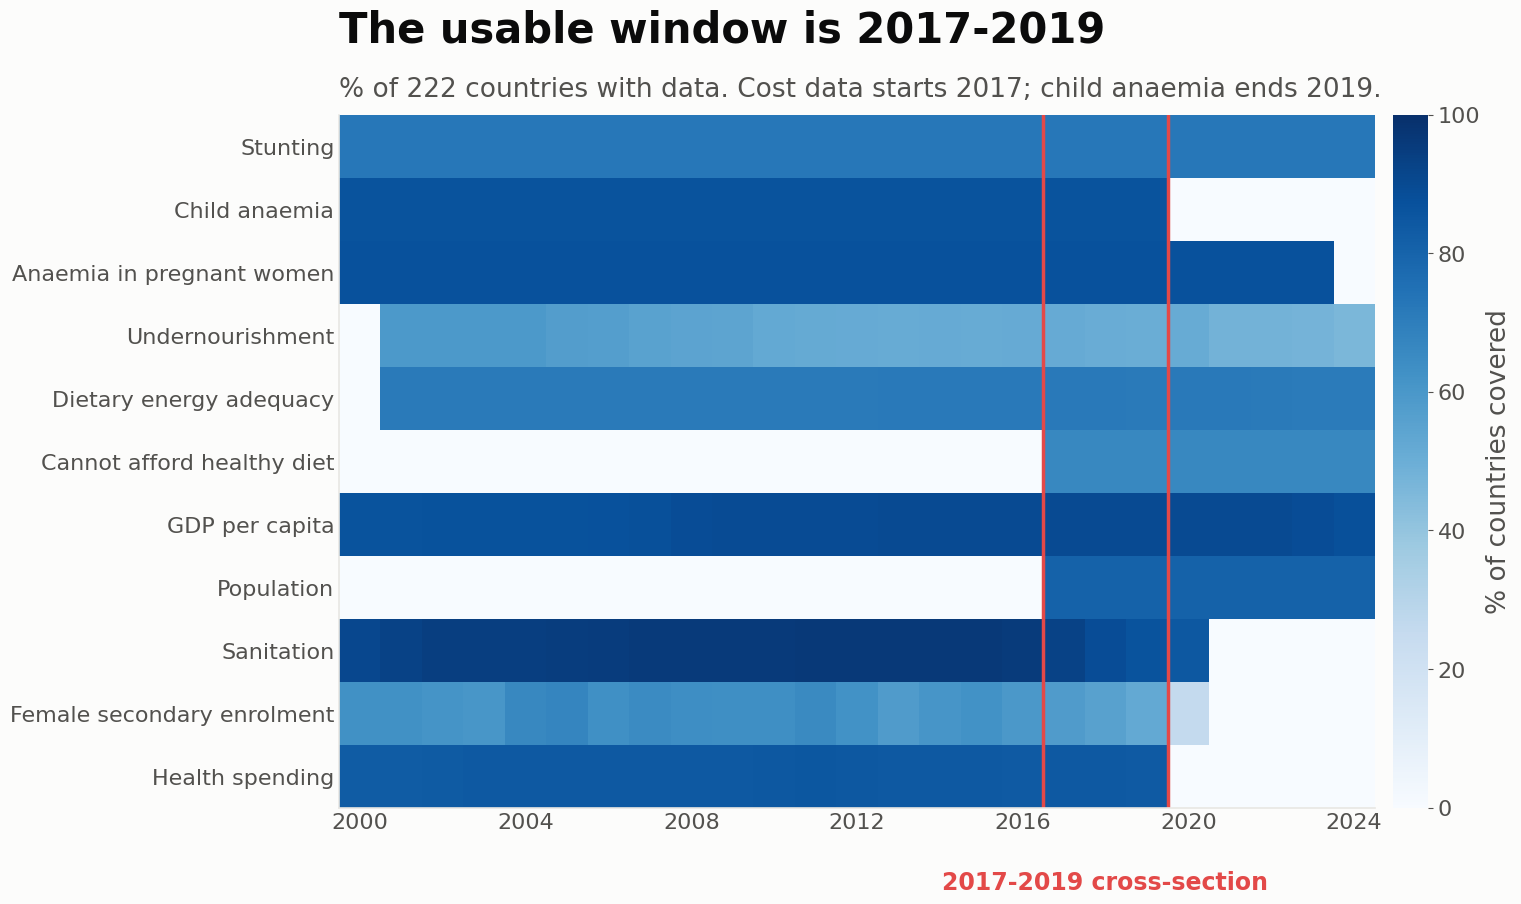

saved figures/fig0a_coverage.png


In [ ]:
# ============ WHY THE WINDOW IS 2017-2019 ============
def fig_coverage(panel):
    """EDA: which indicator-years actually exist. Sequential = magnitude."""
    cols = ["stunting_pct", "child_anaemia_pct", "women_anaemia_preg",
            "undernourishment_pct", "dietary_energy_adequacy_pct",
            "unaffordable_pct", "gdp_pcap_ppp", "pop_total",
            "sanitation_pct", "fem_sec_enroll_pct", "health_exp_pc_ppp"]
    nice = ["Stunting", "Child anaemia", "Anaemia in pregnant women", "Undernourishment",
            "Dietary energy adequacy", "Cannot afford healthy diet",
            "GDP per capita", "Population", "Sanitation",
            "Female secondary enrolment", "Health spending"]
    yrs = list(range(2000, 2025))
    M = np.array([[panel.loc[panel.year == y, c].notna().sum() for y in yrs]
                  for c in cols], float)
    M = M / 222 * 100

    fig, ax = plt.subplots(figsize=(W, H))
    im = ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(0, len(yrs), 4)); ax.set_xticklabels(yrs[::4])
    ax.set_yticks(range(len(cols))); ax.set_yticklabels(nice, fontsize=16)
    _frame(ax, "The usable window is 2017-2019",
           "% of 222 countries with data. Cost data starts 2017; child anaemia "
           "ends 2019.")
    for x in (yrs.index(2017) - .5, yrs.index(2019) + .5):
        ax.axvline(x, color=WORSE, lw=2.5)
    # Below the axis, in axes fraction: placing it above the heatmap in data
    # coords put it on top of the subtitle.
    ax.annotate("2017-2019 cross-section",
                xy=((yrs.index(2018) + .5) / len(yrs), -0.09),
                xycoords="axes fraction", ha="center", va="top",
                color=WORSE, fontweight="bold", fontsize=17)
    cb = fig.colorbar(im, ax=ax, pad=0.015)
    cb.set_label("% of countries covered", color=INK_2)
    cb.outline.set_visible(False)
    _save(fig, "fig0a_coverage.png")


fig_coverage(panel)

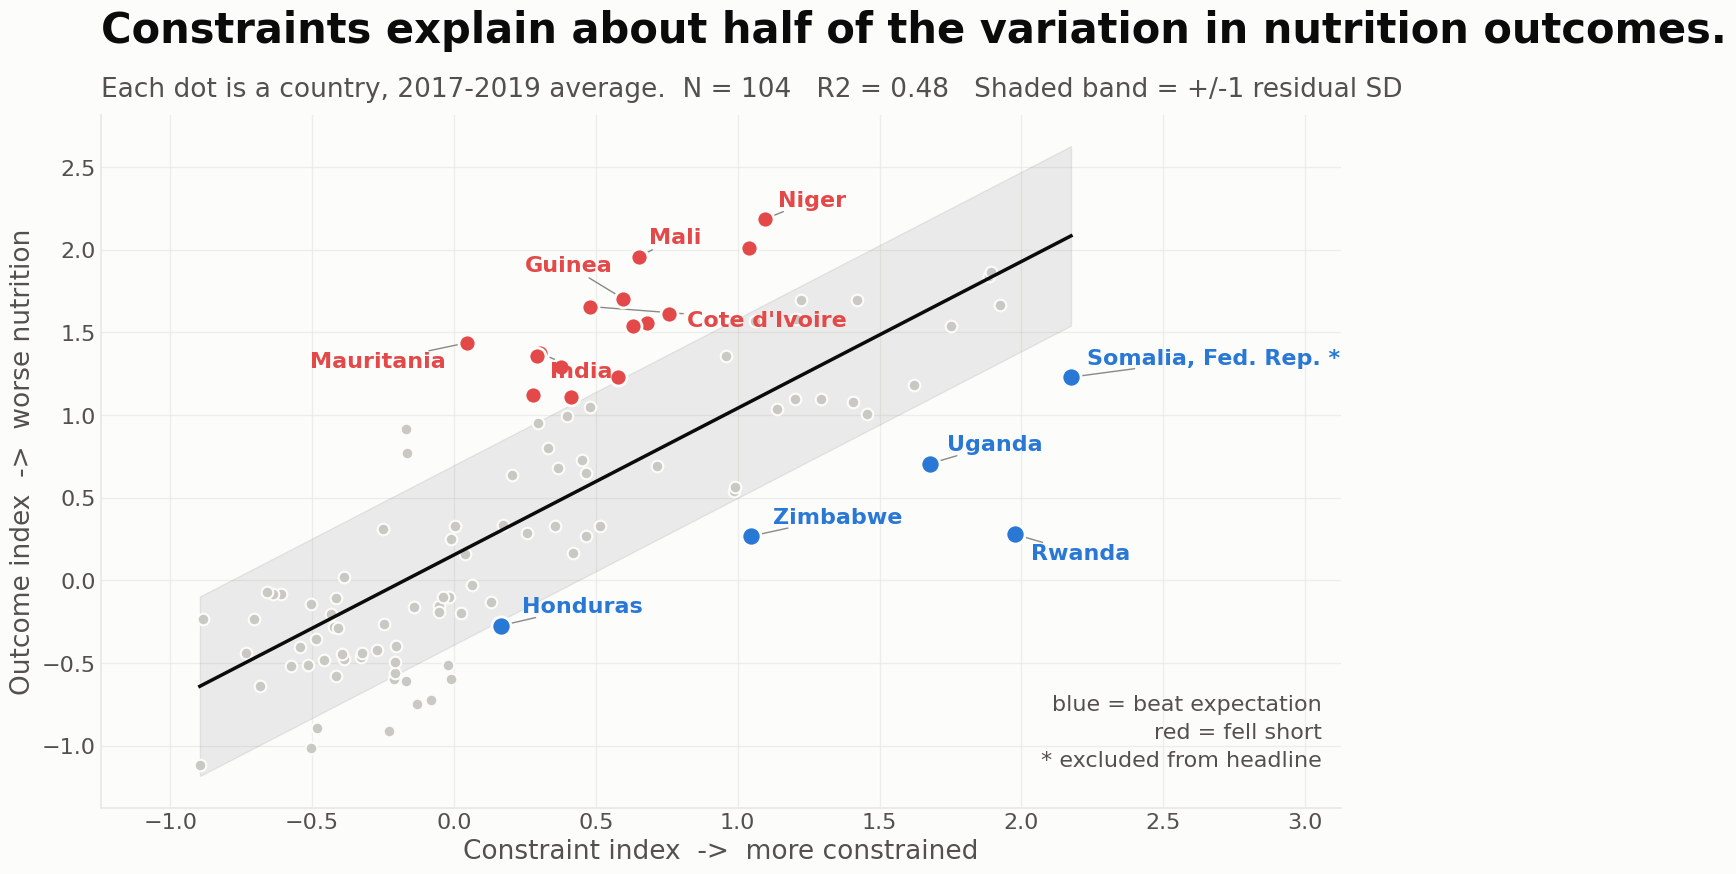

saved figures/fig1_scatter.png


In [ ]:
# ============ THE CORE CLAIM ============
def fig_scatter(d):
    """The core claim: the trend is real, but the spread around it is policy."""
    fig, ax = plt.subplots(figsize=(W, H))
    ax.grid(axis="both", alpha=.7); ax.set_axisbelow(True)

    x, y = d.constraint_index, d.outcome_index
    ax.scatter(x, y, s=70, color=NEUTRAL, edgecolor=SURFACE, linewidth=1.5,
               zorder=2)

    over, under = d[d.headline_over], d[d.headline_under]
    ax.scatter(under.constraint_index, under.outcome_index, s=150, color=WORSE,
               edgecolor=SURFACE, linewidth=2, zorder=4)
    ax.scatter(over.constraint_index, over.outcome_index, s=190, color=BETTER,
               edgecolor=SURFACE, linewidth=2, zorder=5)

    ax.set_xlim(x.min() - .35, x.max() + .95)
    xs = np.linspace(x.min(), x.max(), 100)
    fit = np.polyfit(x, y, 1)
    ax.plot(xs, np.polyval(fit, xs), color=INK, lw=2.5, zorder=3)
    resid_sd = (y - np.polyval(fit, x)).std()
    ax.fill_between(xs, np.polyval(fit, xs) - resid_sd,
                    np.polyval(fit, xs) + resid_sd, color=INK, alpha=.07, zorder=1)

    # Labels are repelled off each other and off the points; without this
    # Zimbabwe/Rwanda and Armenia/Costa Rica overprint each other.
    from adjustText import adjust_text
    texts = []
    for _, r in over.iterrows():
        flag = " *" if r.country in FLAGGED else ""
        texts.append(ax.text(r.constraint_index, r.outcome_index,
                             f"{r.country}{flag}", fontsize=16, color=BETTER,
                             fontweight="bold", zorder=6))
    for _, r in under.nlargest(6, "resid").iterrows():
        texts.append(ax.text(r.constraint_index, r.outcome_index, r.country,
                             fontsize=16, color=WORSE, fontweight="bold",
                             zorder=6))
    adjust_text(texts, ax=ax, expand=(1.35, 1.9),
                arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=1.0,
                                shrinkA=3, shrinkB=6),
                force_text=(.8, 1.4), force_static=(.6, 1.1), max_move=60)

    _frame(ax, "Constraints explain about half of the variation in nutrition outcomes.",
           f"Each dot is a country, 2017-2019 average.  N = {len(d)}   "
           f"R2 = 0.48   Shaded band = +/-1 residual SD",
           "Constraint index  ->  more constrained",
           "Outcome index  ->  worse nutrition")
    ax.text(.985, .06, "blue = beat expectation\nred = fell short\n* excluded "
            "from headline", transform=ax.transAxes, ha="right", fontsize=16,
            color=INK_2, linespacing=1.5)
    _save(fig, "fig1_scatter.png")


fig_scatter(d)

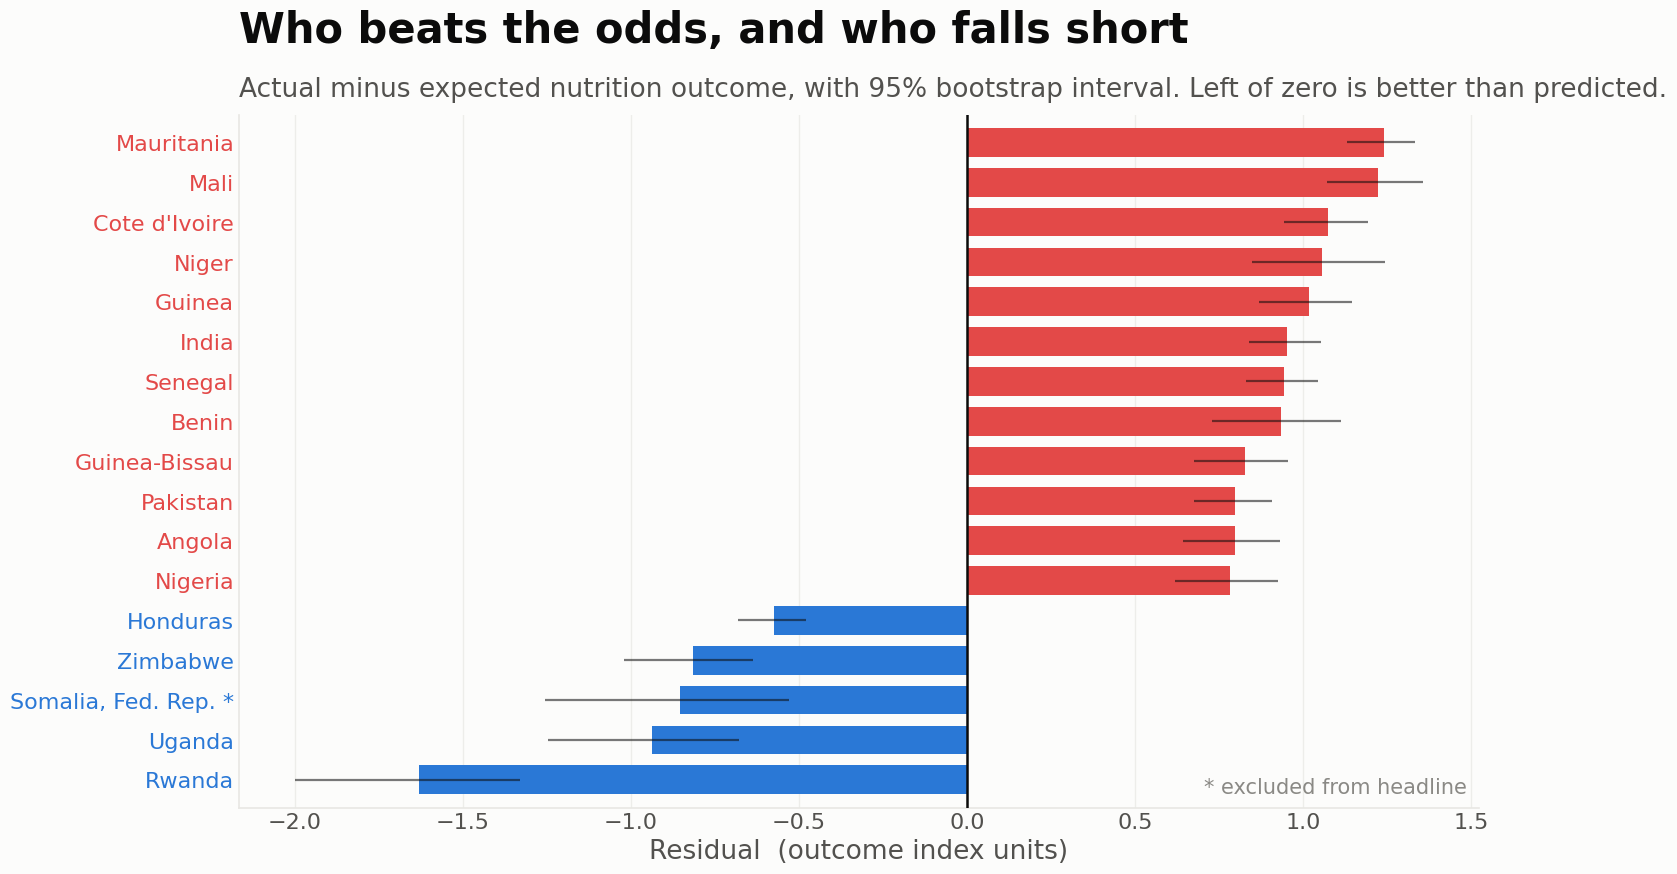

saved figures/fig2_residuals.png


In [ ]:
# ============ WHO BEATS THE ODDS ============
def fig_residuals(d):
    """Ranked deviation with bootstrap CIs. Diverging bars, zero-anchored."""
    over = d[d.headline_over].nsmallest(12, "resid")
    under = d[d.headline_under].nlargest(12, "resid")
    s = pd.concat([under, over]).sort_values("resid")
    y = np.arange(len(s))
    colors = [BETTER if v < 0 else WORSE for v in s.resid]

    fig, ax = plt.subplots(figsize=(W, H))
    ax.grid(axis="x", alpha=.7); ax.set_axisbelow(True)
    ax.barh(y, s.resid, height=.72, color=colors, zorder=3)
    ax.hlines(y, s.resid_lo, s.resid_hi, color=INK, lw=1.6, alpha=.55, zorder=4)
    ax.axvline(0, color=INK, lw=1.8, zorder=5)

    labels = [f"{c} *" if c in FLAGGED else c for c in s.country]
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=16)
    for t, v in zip(ax.get_yticklabels(), s.resid):
        t.set_color(BETTER if v < 0 else WORSE)
    ax.set_ylim(-.7, len(s) - .3)

    _frame(ax, "Who beats the odds, and who falls short",
           "Actual minus expected nutrition outcome, with 95% bootstrap "
           "interval. Left of zero is better than predicted.",
           "Residual  (outcome index units)")
    ax.text(.99, .02, "* excluded from headline", transform=ax.transAxes,
            ha="right", fontsize=15, color=INK_MUTED)
    _save(fig, "fig2_residuals.png")


fig_residuals(d)

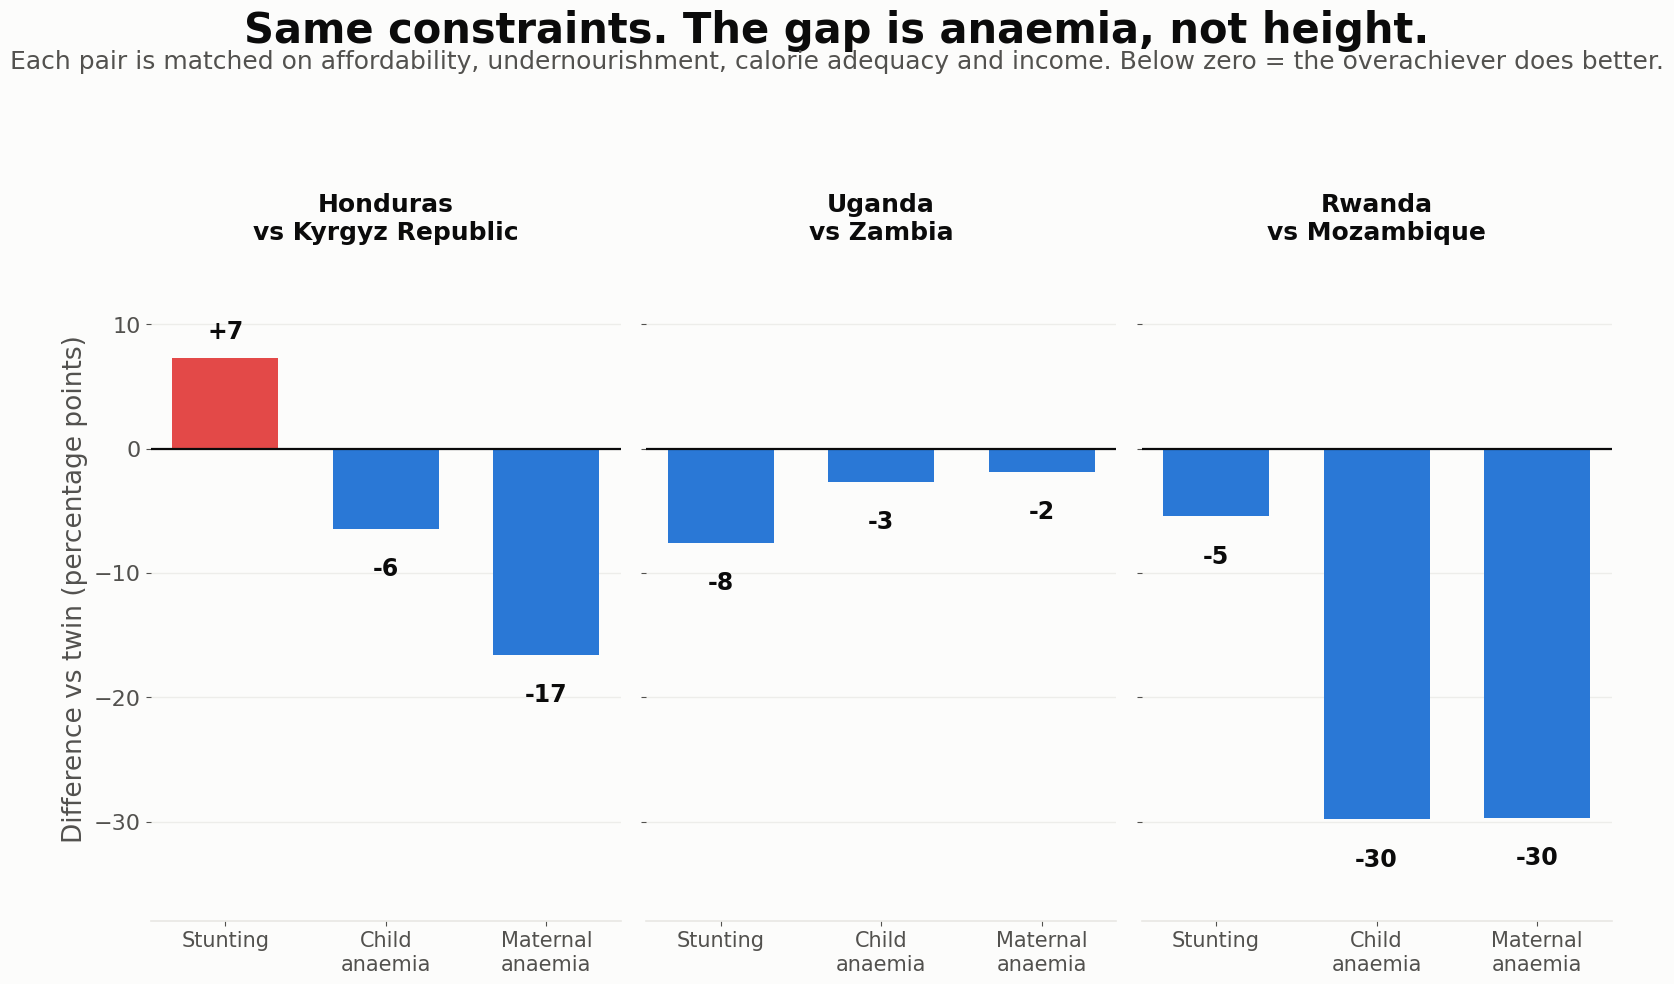

saved figures/fig4_twins.png


In [ ]:
# ============ CONSTRAINT TWINS - THE SHAREABLE VISUAL ============
def fig_twins(twins, d):
    """The shareable visual: same constraints, different outcomes."""
    t = twins.sort_values("distance").head(5)
    fig, axes = plt.subplots(1, len(t), figsize=(W, H), sharey=True)
    outs = ["d_stunting_pct", "d_child_anaemia_pct", "d_women_anaemia_preg"]
    names = ["Stunting", "Child\nanaemia", "Maternal\nanaemia"]

    for ax, (_, r) in zip(axes, t.iterrows()):
        vals = [r[c] for c in outs]
        cols = [BETTER if v < 0 else WORSE for v in vals]
        ax.bar(range(3), vals, color=cols, width=.66, zorder=3)
        ax.axhline(0, color=INK, lw=1.6, zorder=4)
        ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=15)
        ax.grid(axis="y", alpha=.7); ax.set_axisbelow(True)
        ax.margins(y=.22)
        ax.set_title(f"{r.overachiever}\nvs {r.twin}", fontsize=18,
                     fontweight="bold", pad=12, color=INK)
        for i, v in enumerate(vals):
            # Offset in points, not data units: a data-unit offset drifts with
            # the axis range and was colliding with the tick labels.
            ax.annotate(f"{v:+.0f}" if abs(v) >= 1 else f"{v:+.1f}",
                        (i, v), xytext=(0, -20 if v < 0 else 10),
                        textcoords="offset points", ha="center",
                        va="top" if v < 0 else "bottom", fontsize=17,
                        fontweight="bold", color=INK)
        for sp in ("left",): ax.spines[sp].set_visible(False)
    axes[0].set_ylabel("Difference vs twin (percentage points)")
    fig.suptitle("Same constraints. The gap is anaemia, not height.",
                 fontsize=30, fontweight="bold", x=.5, y=1.10, color=INK)
    fig.text(.5, 1.035, "Each pair is matched on affordability, undernourishment,"
             " calorie adequacy and income. Below zero = the overachiever does "
             "better.", ha="center", fontsize=18, color=INK_2)
    fig.tight_layout()
    _save(fig, "fig4_twins.png")


fig_twins(twins, d)

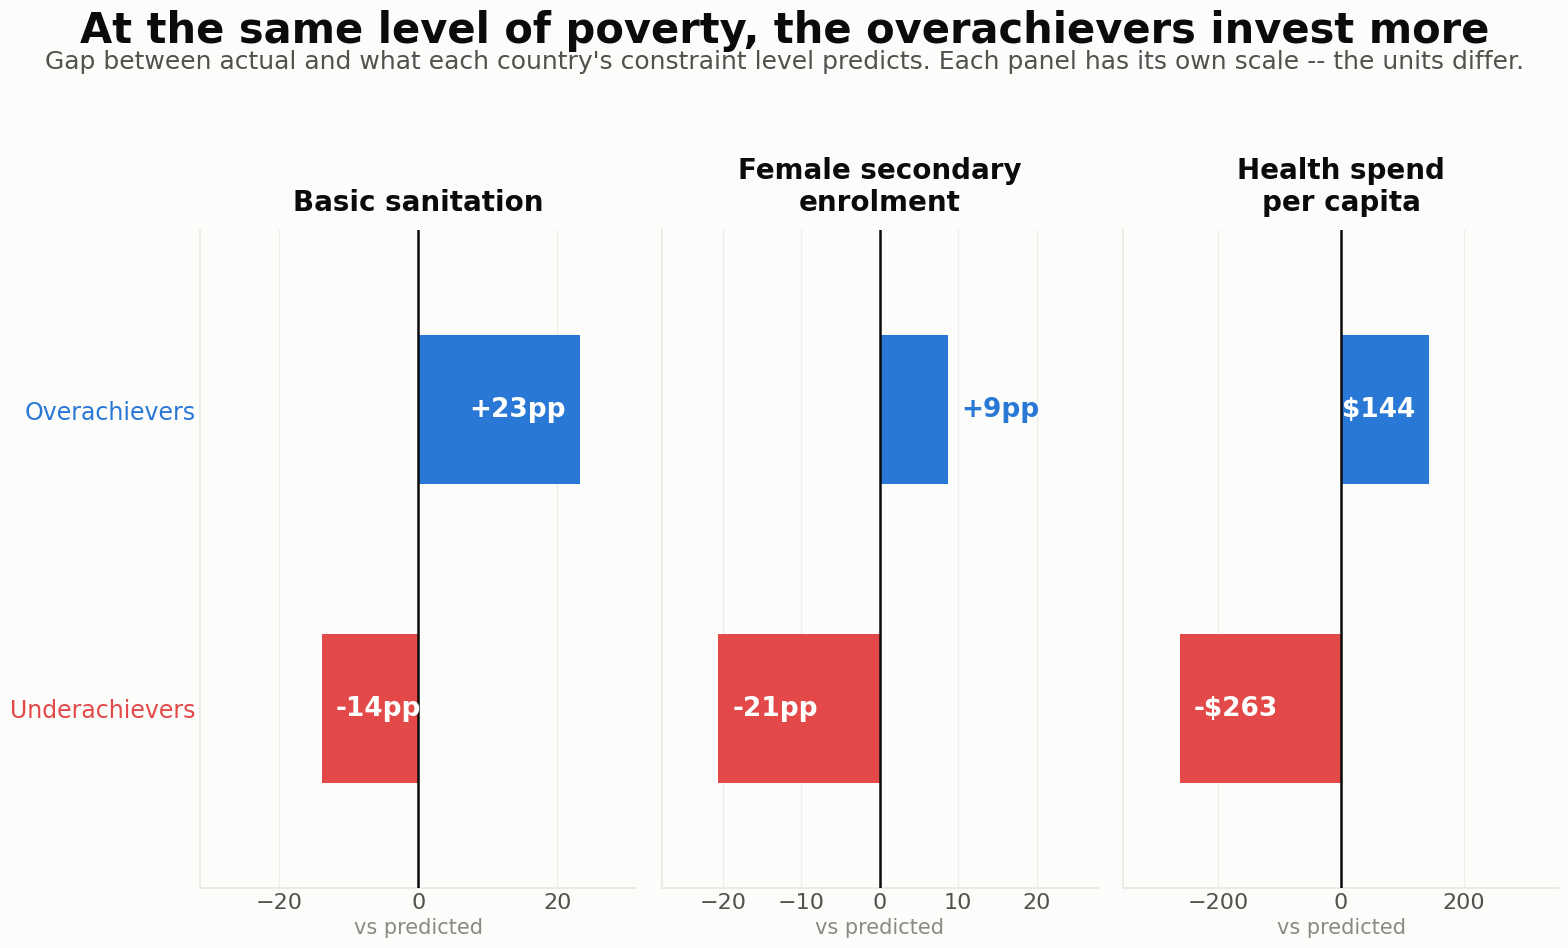

saved figures/fig6_levers.png


In [ ]:
# ============ WHY THEY WIN ============
def fig_levers(d):
    """H3: raw comparison hides the lesson; adjusting for constraint reveals it.

    SMALL MULTIPLES, not a shared axis. Health spend is in dollars (range about
    +/-1000) while sanitation and enrolment are percentage points (range about
    +/-25). Putting all three on one x-scale crushes the pp levers to
    invisibility -- one axis for two units is the classic chart error.
    """
    import statsmodels.api as sm
    levers = [("sanitation_pct", "Basic sanitation", "pp"),
              ("fem_sec_enroll_pct", "Female secondary\nenrolment", "pp"),
              ("health_exp_pc_ppp", "Health spend\nper capita", "$")]

    fig, axes = plt.subplots(1, 3, figsize=(W, H))
    for ax, (col, nice, unit) in zip(axes, levers):
        sub = d.dropna(subset=["constraint_index", col])
        X = sm.add_constant(sub.constraint_index.to_numpy(float))
        fit = sm.OLS(sub[col].to_numpy(float), X).fit()
        adj = pd.Series(sub[col].to_numpy(float) - fit.predict(X), index=sub.index)
        over = adj[sub.headline_over.values].mean()
        under = adj[sub.headline_under.values].mean()

        ax.barh([1, 0], [over, under], height=.5,
                color=[BETTER, WORSE], zorder=3)
        ax.axvline(0, color=INK, lw=1.8, zorder=4)
        ax.set_yticks([1, 0])
        # Category names once, on the first panel only -- repeating them three
        # times is redundant and steals the space the value labels need.
        if ax is axes[0]:
            ax.set_yticklabels(["Overachievers", "Underachievers"], fontsize=17)
            ax.get_yticklabels()[0].set_color(BETTER)
            ax.get_yticklabels()[1].set_color(WORSE)
        else:
            ax.set_yticklabels([])
        ax.set_ylim(-.6, 1.6)
        ax.grid(axis="x", alpha=.7); ax.set_axisbelow(True)
        ax.set_title(nice, fontsize=20, fontweight="bold", pad=14, color=INK)
        ax.tick_params(length=0)
        lim = max(abs(over), abs(under)) * 1.35
        ax.set_xlim(-lim, lim)
        # "-$301" not "$-301"; the sign belongs outside the currency symbol.
        f = ((lambda v: f"{'-' if v < 0 else ''}${abs(v):,.0f}")
             if unit == "$" else (lambda v: f"{v:+.0f}pp"))
        for yy, v in ((1, over), (0, under)):
            # A label wider than its bar gets clipped, so short bars label
            # outside in the mark colour instead of inside in white.
            inside = abs(v) > .38 * lim
            ax.annotate(f(v), (v, yy),
                        xytext=((-10 if v > 0 else 10) if inside
                                else (10 if v > 0 else -10), 0),
                        textcoords="offset points", va="center",
                        ha=("right" if v > 0 else "left") if inside
                           else ("left" if v > 0 else "right"),
                        fontsize=19, fontweight="bold",
                        color="white" if inside else (BETTER if v > 0 else WORSE),
                        zorder=5)
        ax.set_xlabel("vs predicted", fontsize=15, color=INK_MUTED)

    fig.suptitle("At the same level of poverty, the overachievers invest more",
                 fontsize=30, fontweight="bold", x=.5, y=1.06, color=INK)
    fig.text(.5, .995, "Gap between actual and what each country's constraint "
             "level predicts. Each panel has its own scale -- the units differ.",
             ha="center", fontsize=18, color=INK_2)
    fig.tight_layout()
    _save(fig, "fig6_levers.png")


fig_levers(d)

In [ ]:
#============ THE HEADLINE NUMBER ============
def fig_impact(imp): """Scenario impact figure based on Step 7 estimates."""
# Total estimated cases potentially avoided, in millions
kids = imp["kids_anaemia"].sum() / 1e6
preg = imp["preg_anaemia"].sum() / 1e6

# Number of underachieving countries in the CURRENT analysis
n_countries = len(imp)

# Countries contributing the largest estimated child-anaemia impact
top = imp.nlargest(5, "kids_anaemia")

total_kids = imp["kids_anaemia"].sum()
share = (
    100 * top["kids_anaemia"].sum() / total_kids
    if total_kids > 0 else np.nan
)

fig = plt.figure(figsize=(W, H))

fig.text(
    .5, .80,
    f"If the {n_countries} countries falling furthest below expectation "
    "closed half their estimated gap",
    ha="center", fontsize=27, color=INK_2
)

fig.text(
    .5, .565,
    f"{kids:.1f} million",
    ha="center", fontsize=118,
    fontweight="bold", color=BETTER
)

fig.text(
    .5, .49,
    "estimated child anaemia cases could potentially be avoided",
    ha="center", fontsize=32, color=INK
)

fig.text(
    .5, .35,
    f"and {preg:.1f} million estimated pregnancy anaemia cases "
    "could potentially be avoided",
    ha="center", fontsize=25, color=INK_2
)

fig.text(
    .5, .21,
    f"{', '.join(top['country'])} — {share:.0f}% of the estimated "
    "child-anaemia impact",
    ha="center", fontsize=22, color=INK, fontweight="bold"
)

fig.text(
    .5, .10,
    "Scenario: 50% of the estimated gap closed. "
    "Under-5 population and live births from World Bank data.\n"
    "Pregnancy impact uses live births as a conservative denominator. "
    "WHO anaemia and JME stunting are modelled estimates.",
    ha="center", fontsize=15, color=INK_MUTED
)

_save(fig, "fig7_impact.png")
fig_impact(imp)

<Figure size 1600x900 with 0 Axes>

saved figures/fig7_impact.png


In [ ]:
# ============ DOWNLOAD EVERYTHING ============
# Bundles the figures and the result tables into one zip for the video edit.
import os
os.system("cd /content && zip -rq datathon_outputs.zip figures *.csv 2>/dev/null")
print("figures:", sorted(os.listdir("figures")))
print("tables :", sorted(f for f in os.listdir(".") if f.endswith(".csv")))
try:
    from google.colab import files
    files.download("/content/datathon_outputs.zip")
except Exception as e:
    print("not on Colab, or the download was blocked:", type(e).__name__)
    print("Use the folder icon in the left sidebar to download figures/ instead.")

figures: ['fig0a_coverage.png', 'fig1_scatter.png', 'fig2_residuals.png', 'fig4_twins.png', 'fig6_levers.png', 'fig7_impact.png']
tables : ['deviance.csv', 'impact.csv', 'lever_table.csv', 'master.csv', 'twins.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ANANYA — FINAL MODEL RERUN ON CLEANED MASTER
# Expected vs Actual + Candidates + Peer Matching + Validation

In [ ]:
# ============================================================
# ANANYA — FINAL MODEL RERUN ON CLEANED MASTER
# Expected vs Actual + Candidates + Peer Matching + Validation
# ============================================================

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics.pairwise import euclidean_distances


# ------------------------------------------------------------
# 1. KEEP THE YEARS WE ARE USING
# ------------------------------------------------------------

model_master = master[
    (master["year"] >= 2017) &
    (master["year"] <= 2019)
].copy()

# Make sure these are actually numeric
numeric_cols = [
    "gdp_per_capita_ppp",
    "pct_cannot_afford_diet",
    "undernourishment_pct",
    "dietary_energy_adequacy_pct",
    "stunting_pct",
    "child_anaemia_pct",
    "women_anaemia_all"
]

for col in numeric_cols:
    if col in model_master.columns:
        model_master[col] = pd.to_numeric(
            model_master[col],
            errors="coerce"
        )

print("Rows:", len(model_master))
print("Countries:", model_master["country_code"].nunique())


# ------------------------------------------------------------
# 2. COUNTRY-LEVEL AVERAGES
# ------------------------------------------------------------

country_model_data = (
    model_master
    .groupby(["country_code", "country"], as_index=False)
    .agg({
        "gdp_per_capita_ppp": "mean",
        "pct_cannot_afford_diet": "mean",
        "undernourishment_pct": "mean",
        "dietary_energy_adequacy_pct": "mean",
        "stunting_pct": "mean",
        "child_anaemia_pct": "mean",
        "women_anaemia_preg": "mean"
    })
)

print("\nCountry-level dataset:", country_model_data.shape)
display(country_model_data.head())


# ------------------------------------------------------------
# 3. EXPECTED-VS-ACTUAL MODEL FUNCTION
# ------------------------------------------------------------

predictors = [
    "gdp_per_capita_ppp",
    "pct_cannot_afford_diet",
    "undernourishment_pct",
    "dietary_energy_adequacy_pct"
]

def build_outcome_model(df, outcome, label):

    d = df[
        ["country_code", "country"] +
        predictors +
        [outcome]
    ].dropna().copy()

    X = d[predictors]
    y = d[outcome]

    model = LinearRegression()
    model.fit(X, y)

    d["expected"] = model.predict(X)

    # residual = ACTUAL - EXPECTED
    # negative = doing BETTER than expected
    d["residual"] = d[outcome] - d["expected"]

    r2 = r2_score(y, d["expected"])
    mae = mean_absolute_error(y, d["expected"])

    print("\n======================================")
    print(label)
    print("Countries:", len(d))
    print("R²:", round(r2, 3))
    print("MAE:", round(mae, 2))
    print("======================================")

    display(
        d[
            ["country", outcome, "expected", "residual"]
        ]
        .sort_values("residual")
        .head(15)
        .round(2)
    )

    return d, model


# ------------------------------------------------------------
# 4. RUN ALL THREE MODELS
# ------------------------------------------------------------

stunting_results, stunting_model = build_outcome_model(
    country_model_data,
    "stunting_pct",
    "STUNTING"
)

child_results, child_model = build_outcome_model(
    country_model_data,
    "child_anaemia_pct",
    "CHILD ANAEMIA"
)

women_results, women_model = build_outcome_model(
    country_model_data,
    "women_anaemia_preg",
    "ANEMIA IN PREGNANT WOMEN"
)


# ------------------------------------------------------------
# 5. COMBINE THE THREE RESIDUALS
# ------------------------------------------------------------

st = stunting_results[
    ["country_code", "country", "residual"]
].rename(columns={"residual": "stunting_residual"})

ch = child_results[
    ["country_code", "residual"]
].rename(columns={"residual": "child_anemia_residual"})

wo = women_results[
    ["country_code", "residual"]
].rename(columns={"residual": "women_anemia_residual"})


combined_results = (
    st
    .merge(ch, on="country_code", how="inner")
    .merge(wo, on="country_code", how="inner")
)

residual_cols = [
    "stunting_residual",
    "child_anemia_residual",
    "women_anemia_residual"
]

combined_results["better_than_expected_count"] = (
    combined_results[residual_cols] < 0
).sum(axis=1)


# Standardize because the three outcomes use different scales
scaler_residual = StandardScaler()

z = scaler_residual.fit_transform(
    combined_results[residual_cols]
)

combined_results[
    ["stunting_z", "child_z", "women_z"]
] = z

combined_results["combined_score"] = (
    combined_results[
        ["stunting_z", "child_z", "women_z"]
    ].mean(axis=1)
)


# ------------------------------------------------------------
# 6. CONSISTENT OUTPERFORMERS
# ------------------------------------------------------------

consistent_candidates = (
    combined_results[
        combined_results["better_than_expected_count"] == 3
    ]
    .sort_values("combined_score")
    .reset_index(drop=True)
)

print("\n\nTOP CONSISTENT OUTPERFORMERS")
print("Negative combined score = stronger outperformer\n")

display(
    consistent_candidates[
        [
            "country",
            "stunting_residual",
            "child_anemia_residual",
            "women_anemia_residual",
            "combined_score",
            "better_than_expected_count"
        ]
    ]
    .head(20)
    .round(2)
)


# ------------------------------------------------------------
# 7. ALSO CHECK A 2-OUTCOME ROBUSTNESS VERSION
#    because women's anaemia model was weak previously
# ------------------------------------------------------------

robust_2 = combined_results.copy()

two_cols = [
    "stunting_residual",
    "child_anemia_residual"
]

robust_2["better_2"] = (
    robust_2[two_cols] < 0
).sum(axis=1)

z2 = StandardScaler().fit_transform(
    robust_2[two_cols]
)

robust_2["score_2outcome"] = z2.mean(axis=1)

robust_2 = (
    robust_2[
        robust_2["better_2"] == 2
    ]
    .sort_values("score_2outcome")
)

print("\n\n2-OUTCOME ROBUSTNESS CHECK")
print("(Stunting + Child Anaemia only)\n")

display(
    robust_2[
        [
            "country",
            "stunting_residual",
            "child_anemia_residual",
            "score_2outcome"
        ]
    ]
    .head(20)
    .round(2)
)


# ------------------------------------------------------------
# 8. CREATE PEER-MATCHING DATA
# ------------------------------------------------------------

peer_features_3 = [
    "gdp_per_capita_ppp",
    "pct_cannot_afford_diet",
    "undernourishment_pct"

]

all_peer_data = (
    country_model_data[
        [
            "country_code",
            "country",
            "gdp_per_capita_ppp",
            "pct_cannot_afford_diet",
            "undernourishment_pct",
            "dietary_energy_adequacy_pct",
            "stunting_pct",
            "child_anaemia_pct",
            "women_anaemia_preg"
        ]
    ]
    .merge(
        combined_results[
            ["country_code", "combined_score"]
        ],
        on="country_code",
        how="inner"
    )
)

all_peer_data = all_peer_data.dropna(
    subset=peer_features_3
).reset_index(drop=True)

print("\nCountries available for peer matching:",
      len(all_peer_data))


# ------------------------------------------------------------
# 9. THREE-VARIABLE PEER MATCHING
# ------------------------------------------------------------

peer_scaler_3 = StandardScaler()

scaled3 = peer_scaler_3.fit_transform(
    all_peer_data[peer_features_3]
)

scaled3 = pd.DataFrame(
    scaled3,
    columns=peer_features_3,
    index=all_peer_data.index
)

peer_rows_3 = []

candidate_names = set(
    consistent_candidates["country"]
)


for idx, candidate in all_peer_data.iterrows():

    if candidate["country"] not in candidate_names:
        continue

    # We want comparison countries that perform WORSE overall
    possible_peers = all_peer_data[
        all_peer_data["combined_score"] >
        candidate["combined_score"]
    ].copy()

    possible_peers = possible_peers[
        possible_peers["country"] != candidate["country"]
    ]

    if len(possible_peers) == 0:
        continue

    candidate_vector = scaled3.loc[[idx]]

    peer_vectors = scaled3.loc[
        possible_peers.index
    ]

    distances = euclidean_distances(
        candidate_vector,
        peer_vectors
    )[0]

    possible_peers["distance"] = distances

    nearest = possible_peers.nsmallest(
        3,
        "distance"
    )

    for _, peer in nearest.iterrows():

        peer_rows_3.append({
            "outperformer": candidate["country"],
            "peer": peer["country"],
            "distance": peer["distance"],

            # positive gap means outperformer has LOWER/better prevalence
            "stunting_gap":
                peer["stunting_pct"] -
                candidate["stunting_pct"],

            "child_anemia_gap":
                peer["child_anaemia_pct"] -
                candidate["child_anaemia_pct"],

            "women_anemia_gap":
                peer["women_anaemia_preg"] -
                candidate["women_anaemia_preg"]
        })


peer_matches_3 = pd.DataFrame(peer_rows_3)

peer_matches_3["outcomes_better"] = (
    peer_matches_3[
        [
            "stunting_gap",
            "child_anemia_gap",
            "women_anemia_gap"
        ]
    ] > 0
).sum(axis=1)

print("\n\nTHREE-VARIABLE PEER MATCHES")

display(
    peer_matches_3
    .sort_values(
        ["outcomes_better", "distance"],
        ascending=[False, True]
    )
    .head(30)
    .round(2)
)


# ------------------------------------------------------------
# 10. FOUR-VARIABLE PEER MATCHING SENSITIVITY
# ------------------------------------------------------------

peer_features_4 = [
    "gdp_per_capita_ppp",
    "pct_cannot_afford_diet",
    "undernourishment_pct",
    "dietary_energy_adequacy_pct"
]

peer4_data = all_peer_data.dropna(
    subset=peer_features_4
).copy()

peer_scaler_4 = StandardScaler()

scaled4_array = peer_scaler_4.fit_transform(
    peer4_data[peer_features_4]
)

scaled4 = pd.DataFrame(
    scaled4_array,
    columns=peer_features_4,
    index=peer4_data.index
)

peer_rows_4 = []

for idx, candidate in peer4_data.iterrows():

    if candidate["country"] not in candidate_names:
        continue

    possible_peers = peer4_data[
        peer4_data["combined_score"] >
        candidate["combined_score"]
    ].copy()

    possible_peers = possible_peers[
        possible_peers["country"] != candidate["country"]
    ]

    if len(possible_peers) == 0:
        continue

    distances = euclidean_distances(
        scaled4.loc[[idx]],
        scaled4.loc[possible_peers.index]
    )[0]

    possible_peers["distance_4var"] = distances

    nearest = possible_peers.nsmallest(
        3,
        "distance_4var"
    )

    for _, peer in nearest.iterrows():

        peer_rows_4.append({
            "outperformer": candidate["country"],
            "peer": peer["country"],
            "distance_4var": peer["distance_4var"]
        })


peer_matches_4 = pd.DataFrame(peer_rows_4)


# ------------------------------------------------------------
# 11. COMBINE 3-VAR + 4-VAR RESULTS
# ------------------------------------------------------------

peer_comparison = peer_matches_3.merge(
    peer_matches_4,
    on=["outperformer", "peer"],
    how="inner"
)

peer_comparison["avg_distance"] = (
    peer_comparison["distance"] +
    peer_comparison["distance_4var"]
) / 2


print("\n\nSTRONGEST PEER PAIRS")
print("Prefer: outcomes_better = 3 AND low avg_distance\n")

display(
    peer_comparison
    .sort_values(
        ["outcomes_better", "avg_distance"],
        ascending=[False, True]
    )
    .head(25)
    .round(2)
)


# ------------------------------------------------------------
# 12. CROSS-VALIDATION
# ------------------------------------------------------------

def cross_validate_outcome(df, outcome):

    d = df[
        predictors + [outcome]
    ].dropna().copy()

    X = d[predictors]
    y = d[outcome]

    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    model = LinearRegression()

    r2_scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="r2"
    )

    mae_scores = -cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_mean_absolute_error"
    )

    return {
        "outcome": outcome,
        "countries": len(d),
        "CV_R2_mean": r2_scores.mean(),
        "CV_R2_std": r2_scores.std(),
        "CV_MAE_mean": mae_scores.mean()
    }


cv_results = pd.DataFrame([
    cross_validate_outcome(
        country_model_data,
        "stunting_pct"
    ),
    cross_validate_outcome(
        country_model_data,
        "child_anaemia_pct"
    ),
    cross_validate_outcome(
        country_model_data,
        "women_anaemia_preg"
    )
])


print("\n\nCROSS-VALIDATION RESULTS")
display(cv_results.round(3))

Rows: 666
Countries: 222

Country-level dataset: (222, 9)


,country_code,country,gdp_per_capita_ppp,pct_cannot_afford_diet,undernourishment_pct,dietary_energy_adequacy_pct,stunting_pct,child_anaemia_pct,women_anaemia_preg
0,ABW,Aruba,39115.359241,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,2927.545391,NaN,23.133333,106.333333,NaN,44.533333,32.233333
2,AGO,Angola,10144.328673,63.900000,16.200000,113.666667,39.1,62.266667,45.533333
3,AIA,Anguilla,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ALB,Albania,16097.147969,22.833333,4.300000,135.000000,11.1,29.633333,24.466667



STUNTING
Countries: 81
R²: 0.543
MAE: 5.66


,country,stunting_pct,expected,residual
44,Cabo Verde,6.20,22.38,-16.18
82,Guyana,9.73,24.75,-15.02
64,Fiji,6.30,19.72,-13.42
86,Haiti,21.53,33.56,-12.02
92,"Iran, Islamic Rep.",5.10,15.34,-10.24
40,"Congo, Rep.",18.90,29.01,-10.11
181,Sao Tome and Principe,12.90,22.51,-9.61
35,Chile,1.67,11.17,-9.51
133,Mongolia,8.63,18.02,-9.39
97,Jamaica,6.40,15.41,-9.01



CHILD ANAEMIA
Countries: 82
R²: 0.55
MAE: 9.99


...

,outperformer,peer,distance,stunting_gap,child_anemia_gap,women_anemia_gap,outcomes_better
6,Chile,Bulgaria,0.16,4.50,4.13,3.77,3
27,"Iran, Islamic Rep.",Peru,0.18,7.37,4.07,2.27,3
54,Eswatini,Angola,0.21,16.83,18.83,16.70,3
39,Sri Lanka,Peru,0.23,0.33,5.63,1.60,3
48,Peru,"Egypt, Arab Rep.",0.28,3.67,2.03,4.93,3
28,"Iran, Islamic Rep.","Egypt, Arab Rep.",0.28,11.03,6.10,7.20,3
36,Kenya,Tanzania,0.31,10.50,14.57,9.30,3
10,Colombia,Peru,0.34,0.90,8.20,1.47,3
55,Eswatini,Nigeria,0.35,12.13,26.23,18.13,3
11,Colombia,"Egypt, Arab Rep.",0.41,4.57,10.23,6.40,3




STRONGEST PEER PAIRS
Prefer: outcomes_better = 3 AND low avg_distance



,outperformer,peer,distance,stunting_gap,child_anemia_gap,women_anemia_gap,outcomes_better,distance_4var,avg_distance
13,"Iran, Islamic Rep.",Peru,0.18,7.37,4.07,2.27,3,0.19,0.18
22,Sri Lanka,Peru,0.23,0.33,5.63,1.60,3,0.28,0.25
2,Chile,Bulgaria,0.16,4.50,4.13,3.77,3,0.53,0.35
30,Eswatini,Angola,0.21,16.83,18.83,16.70,3,0.68,0.45
35,Uganda,Liberia,0.49,3.00,20.33,12.67,3,0.49,0.49
4,Colombia,"Egypt, Arab Rep.",0.41,4.57,10.23,6.40,3,0.63,0.52
26,Mongolia,South Africa,0.49,13.53,21.60,0.80,3,0.56,0.52
21,Kenya,Sierra Leone,0.49,6.43,32.37,13.40,3,0.64,0.57
18,Jamaica,Sri Lanka,0.57,5.73,1.13,0.23,3,0.69,0.63
16,Iraq,Gabon,0.82,1.67,29.67,23.13,3,0.88,0.85




CROSS-VALIDATION RESULTS


,outcome,countries,CV_R2_mean,CV_R2_std,CV_MAE_mean
0,stunting_pct,81,0.452,0.097,6.103
1,child_anaemia_pct,82,0.382,0.261,10.842
2,women_anaemia_preg,81,0.132,0.298,7.520


In [ ]:
final_pair_check = peer_comparison.copy()

final_pair_check["better_main_2"] = (
    (final_pair_check["stunting_gap"] > 0) &
    (final_pair_check["child_anemia_gap"] > 0)
)

final_pair_check["main_gap_avg"] = (
    final_pair_check["stunting_gap"] +
    final_pair_check["child_anemia_gap"]
) / 2

final_pair_check = (
    final_pair_check[
        final_pair_check["better_main_2"]
    ]
    .sort_values(
        ["avg_distance", "main_gap_avg"],
        ascending=[True, False]
    )
)

display(
    final_pair_check[
        [
            "outperformer",
            "peer",
            "avg_distance",
            "stunting_gap",
            "child_anemia_gap",
            "women_anemia_gap",
            "main_gap_avg"
        ]
    ]
    .head(50)
    .round(2)
)

,outperformer,peer,avg_distance,stunting_gap,child_anemia_gap,women_anemia_gap,main_gap_avg
13,"Iran, Islamic Rep.",Peru,0.18,7.37,4.07,2.27,5.72
22,Sri Lanka,Peru,0.25,0.33,5.63,1.60,2.98
29,Paraguay,Albania,0.30,6.07,1.20,-2.40,3.63
8,Fiji,South Africa,0.34,15.87,2.93,-2.77,9.40
2,Chile,Bulgaria,0.35,4.50,4.13,3.77,4.32
30,Eswatini,Angola,0.45,16.83,18.83,16.70,17.83
35,Uganda,Liberia,0.49,3.00,20.33,12.67,11.67
10,Guyana,Indonesia,0.52,17.57,8.40,-3.00,12.98
4,Colombia,"Egypt, Arab Rep.",0.52,4.57,10.23,6.40,7.40
26,Mongolia,South Africa,0.52,13.53,21.60,0.80,17.57


In [ ]:
pairs_to_check = [
    ("Eswatini", "Angola"),
    ("Kenya", "Sierra Leone"),
    ("Uganda", "Liberia")
]

rows = []

for a, b in pairs_to_check:
    ca = all_peer_data[all_peer_data["country"] == a].iloc[0]
    cb = all_peer_data[all_peer_data["country"] == b].iloc[0]

    rows.append({
        "outperformer": a,
        "peer": b,

        "GDP_outperformer": ca["gdp_per_capita_ppp"],
        "GDP_peer": cb["gdp_per_capita_ppp"],

        "diet_unaffordable_outperformer": ca["pct_cannot_afford_diet"],
        "diet_unaffordable_peer": cb["pct_cannot_afford_diet"],

        "undernourishment_outperformer": ca["undernourishment_pct"],
        "undernourishment_peer": cb["undernourishment_pct"],

        "energy_adequacy_outperformer": ca["dietary_energy_adequacy_pct"],
        "energy_adequacy_peer": cb["dietary_energy_adequacy_pct"],
    })

pair_details = pd.DataFrame(rows)

display(pair_details.round(2))

,outperformer,peer,GDP_outperformer,GDP_peer,diet_unaffordable_outperformer,diet_unaffordable_peer,undernourishment_outperformer,undernourishment_peer,energy_adequacy_outperformer,energy_adequacy_peer
0,Eswatini,Angola,9779.41,10144.33,68.30,63.90,15.47,16.20,106.00,113.67
1,Kenya,Sierra Leone,5012.08,2791.16,70.57,63.93,25.07,27.83,98.67,103.67
2,Uganda,Liberia,2615.71,1628.35,76.07,66.07,37.17,35.57,97.00,97.00


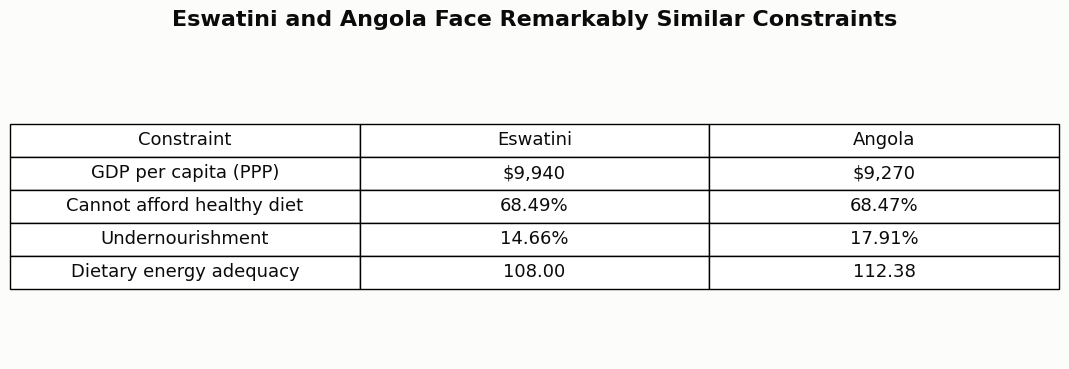

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
ax.axis("off")

columns = ["Constraint", "Eswatini", "Angola"]
data = [
    ["GDP per capita (PPP)", "$9,940", "$9,270"],
    ["Cannot afford healthy diet", "68.49%", "68.47%"],
    ["Undernourishment", "14.66%", "17.91%"],
    ["Dietary energy adequacy", "108.00", "112.38"]
]

table = ax.table(
    cellText=data,
    colLabels=columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 2)

plt.title(
    "Eswatini and Angola Face Remarkably Similar Constraints",
    fontsize=16,
    weight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

In [ ]:
pairs_to_check = [
    ("Iran, Islamic Rep.", "Peru"),
    ("Sri Lanka", "Peru"),
    ("Paraguay", "Albania")
]

rows = []

for a, b in pairs_to_check:
    ca = all_peer_data[all_peer_data["country"] == a].iloc[0]
    cb = all_peer_data[all_peer_data["country"] == b].iloc[0]

    rows.append({
        "outperformer": a,
        "peer": b,

        "GDP_outperformer": ca["gdp_per_capita_ppp"],
        "GDP_peer": cb["gdp_per_capita_ppp"],

        "diet_unaffordable_outperformer": ca["pct_cannot_afford_diet"],
        "diet_unaffordable_peer": cb["pct_cannot_afford_diet"],

        "undernourishment_outperformer": ca["undernourishment_pct"],
        "undernourishment_peer": cb["undernourishment_pct"],

        "energy_adequacy_outperformer": ca["dietary_energy_adequacy_pct"],
        "energy_adequacy_peer": cb["dietary_energy_adequacy_pct"],
    })

pair_details = pd.DataFrame(rows)

display(pair_details.round(2))

,outperformer,peer,GDP_outperformer,GDP_peer,diet_unaffordable_outperformer,diet_unaffordable_peer,undernourishment_outperformer,undernourishment_peer,energy_adequacy_outperformer,energy_adequacy_peer
0,"Iran, Islamic Rep.",Peru,15457.95,15304.38,34.57,33.53,7.90,6.17,120.67,121.0
1,Sri Lanka,Peru,14656.59,15304.38,30.07,33.53,4.73,6.17,119.00,121.0
2,Paraguay,Albania,15409.60,16097.15,25.87,22.83,2.77,4.30,131.33,135.0


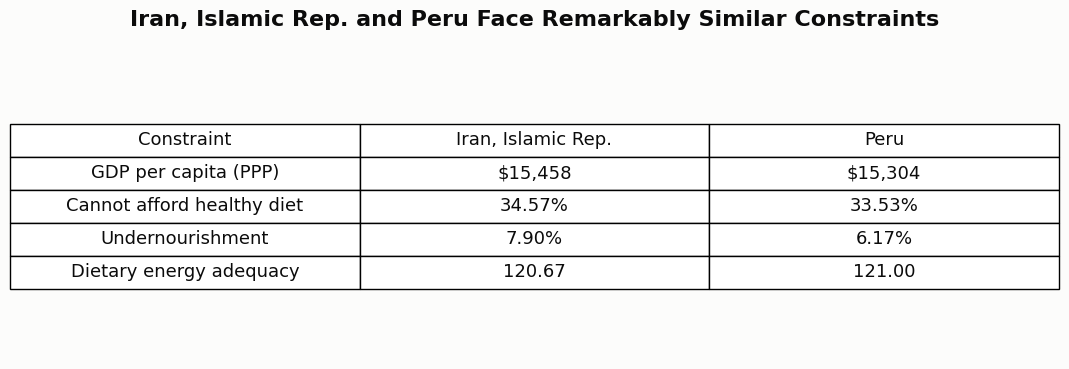

In [ ]:
import matplotlib.pyplot as plt

def fig_pair_table(pair_row, title):
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.axis("off")

    columns = ["Constraint", pair_row["outperformer"], pair_row["peer"]]
    data = [
        ["GDP per capita (PPP)",
         f"${pair_row['GDP_outperformer']:,.0f}",
         f"${pair_row['GDP_peer']:,.0f}"],
        ["Cannot afford healthy diet",
         f"{pair_row['diet_unaffordable_outperformer']:.2f}%",
         f"{pair_row['diet_unaffordable_peer']:.2f}%"],
        ["Undernourishment",
         f"{pair_row['undernourishment_outperformer']:.2f}%",
         f"{pair_row['undernourishment_peer']:.2f}%"],
        ["Dietary energy adequacy",
         f"{pair_row['energy_adequacy_outperformer']:.2f}",
         f"{pair_row['energy_adequacy_peer']:.2f}"],
    ]

    table = ax.table(
        cellText=data,
        colLabels=columns,
        cellLoc="center",
        loc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(13)
    table.scale(1, 2)

    plt.title(title, fontsize=16, weight="bold", pad=20)
    plt.tight_layout()
    plt.show()

row = pair_details.iloc[0]   # Iran vs Peru
fig_pair_table(
    row,
    f"{row['outperformer']} and {row['peer']} Face Remarkably Similar Constraints"
)

In [ ]:
display(pair_details)

,outperformer,peer,GDP_outperformer,GDP_peer,diet_unaffordable_outperformer,diet_unaffordable_peer,undernourishment_outperformer,undernourishment_peer,energy_adequacy_outperformer,energy_adequacy_peer
0,"Iran, Islamic Rep.",Peru,15457.949260,15304.377049,34.566667,33.533333,7.900000,6.166667,120.666667,121.0
1,Sri Lanka,Peru,14656.585002,15304.377049,30.066667,33.533333,4.733333,6.166667,119.000000,121.0
2,Paraguay,Albania,15409.601495,16097.147969,25.866667,22.833333,2.766667,4.300000,131.333333,135.0


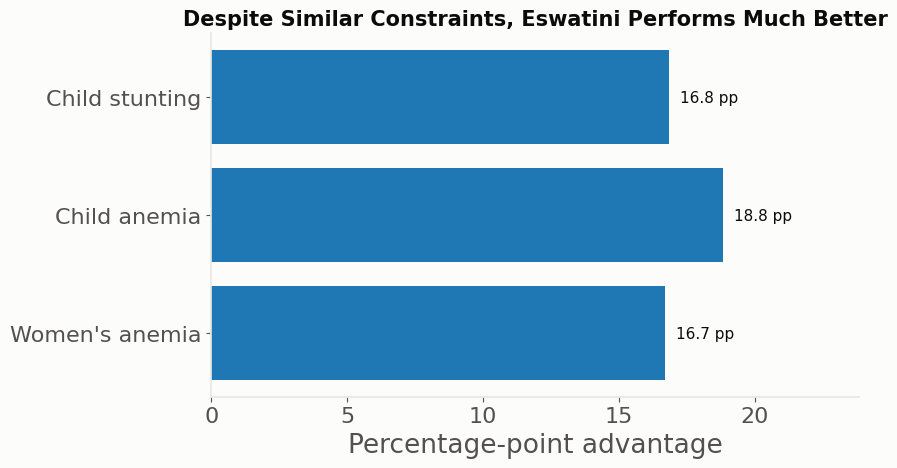

In [ ]:
# VISUAL 2 — NUTRITION OUTCOME GAP

import matplotlib.pyplot as plt

outcomes = [
    "Child stunting",
    "Child anemia",
    "Women's anemia"
]

advantages = [
    16.83,
    18.83,
    16.70
]

plt.figure(figsize=(9,5))

bars = plt.barh(outcomes, advantages)

plt.xlabel("Percentage-point advantage")
plt.title(
    "Despite Similar Constraints, Eswatini Performs Much Better",
    fontsize=15,
    weight="bold"
)

plt.gca().invert_yaxis()

for bar, value in zip(bars, advantages):
    plt.text(
        value + 0.4,
        bar.get_y() + bar.get_height()/2,
        f"{value:.1f} pp",
        va="center",
        fontsize=11
    )

plt.xlim(0, max(advantages) + 5)
plt.tight_layout()
plt.show()

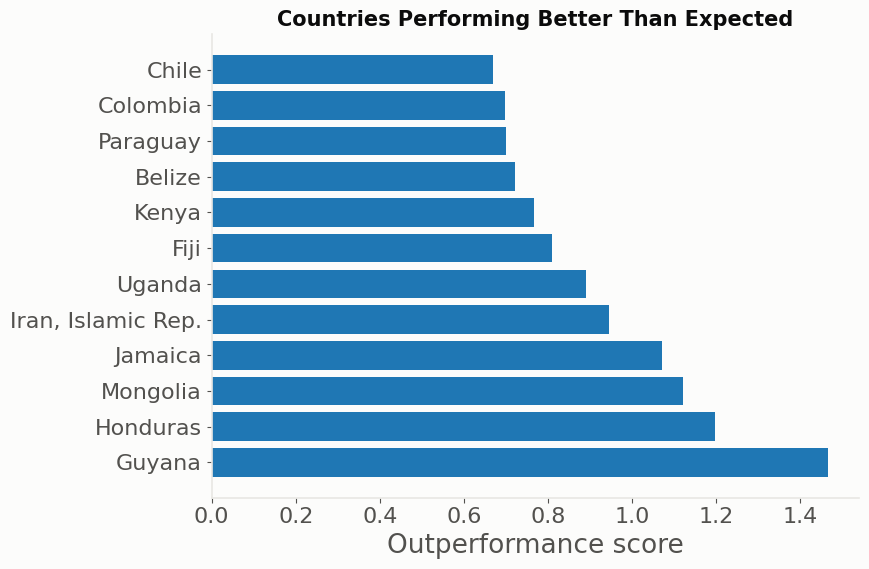

In [ ]:
# VISUAL 3 — TOP BETTER-THAN-EXPECTED COUNTRIES

top = consistent_candidates.head(12).copy()

top = top.sort_values("combined_score", ascending=True)

plt.figure(figsize=(9,6))

plt.barh(
    top["country"],
    -top["combined_score"]
)

plt.xlabel("Outperformance score")
plt.title(
    "Countries Performing Better Than Expected",
    fontsize=15,
    weight="bold"
)

plt.tight_layout()
plt.show()

### Interpretation: Why might Eswatini outperform Angola?

The model identifies Eswatini as a positive deviant relative to Angola: the two countries face similar economic and food-security constraints, but Eswatini achieves substantially better maternal and child nutrition outcomes.

External evidence suggests several possible protective factors in Eswatini, including stronger breastfeeding practices, sanitation coverage, maternal/newborn healthcare, and community-based nutrition interventions focused on the first 1,000 days.

These factors are plausible explanations rather than proven causal effects. The model identifies the outcome gap; further policy analysis is needed to determine which interventions contribute most strongly to it.

### Key takeaway
Similar economic and food-security constraints do not necessarily lead to similar nutrition outcomes. Strengthening the systems surrounding mothers and children may help countries achieve better outcomes even before underlying economic constraints are fully resolved.